<a href="https://colab.research.google.com/github/enzoalvino00/Analitica-Empresarial-Integrada/blob/main/Unidad_4%20_Calidad%20y%20Gobierno%20de%20Datos/Semana_13/Anal%C3%ADtica_Empresarial_Integrada_Lab13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---
# **TECSUP 2026-II - ANALÍTICA EMPRESARIAL INTEGRADA**

## **LABORATORIO DIRIGIDO N.° 13: Auditoría de un modelo: sesgo, explicabilidad y cumplimiento**

| | |
|---|---|
| **Docente** | Pilar Rocío Sayán Mejía |
| **Laboratorio** | Auditoría de un modelo: sesgo, explicabilidad y cumplimiento |
| **N.° de laboratorio** | 13 |
| **Tema** | Gobierno de datos, auditoría de sesgo algorítmico por subgrupos y explicabilidad mediante SHAP |
| **Caso** | Clasificación del nivel de ingresos y auditoría de equidad algorítmica |
| **Fuente de datos** | UCI Machine Learning Repository (ID 2) |
| **Dataset** | Adult (Census Income) |
| **Plan curricular** | Big Data y Ciencia de Datos |
| **Código** | C28 |
| **Periodo académico** | 2026-II |

---

**Estudiante:** Enzo Gabriel Alvino Carhuaricra
**Sección:** 6C28
**Fecha:** 11/11/2026

---
**Pregunta:** ¿qué brechas de un modelo merecen una revisión empresarial antes de autorizar su uso, sin confundir una diferencia estadística entre grupos con una discriminación demostrada?

> Las variables sensibles se usan para **auditoría**, no para recomendar decisiones discriminatorias.
> SHAP explica el comportamiento del modelo; **no demuestra causalidad**.
> Este checklist es **académico**: no constituye certificación legal.

> Referencias: Molnar, C. *Interpretable Machine Learning*, 2.ª ed. · DAMA International, *DAMA-DMBOK*, 2.ª ed. revisada · Ley N.° 29733 y DS 016-2024-JUS · Ley N.° 31814 y DS 115-2025-PCM.

## **Configuración del entorno**

Se instalan las tres librerías que Colab no incluye por defecto y se importan las dependencias en un solo bloque, de modo que el notebook pueda ejecutarse de principio a fin sin interrupciones. Se fija la semilla `42` en la partición, en el modelo y en la submuestra de SHAP: sin esa fijación, dos ejecuciones del mismo notebook producirían brechas distintas y la auditoría dejaría de ser verificable.

In [1]:
# ══════════════════════════════════════════════════════════════
# 1. INSTALACIÓN DE DEPENDENCIAS
# ══════════════════════════════════════════════════════════════

# Instalación de las librerías que Colab no incluye por defecto
%pip install -q ucimlrepo shap plotly                 ### ucimlrepo accede a UCI, shap explica el modelo y plotly construye los gráficos


In [2]:
# ══════════════════════════════════════════════════════════════
# 2. IMPORTACIÓN DE LIBRERÍAS Y CONFIGURACIÓN DEL ENTORNO
# ══════════════════════════════════════════════════════════════

# Silencia las advertencias de las librerías para facilitar la lectura de los resultados
import warnings                                       ### Módulo de control de advertencias de Python
warnings.filterwarnings("ignore")                     ### Oculta los avisos no críticos durante la ejecución

# Manipulación de datos y construcción de gráficos
import numpy as np, pandas as pd                      ### numpy para operaciones numéricas y pandas para datos estructurados
import plotly.express as px                           ### Gráficos interactivos para la auditoría por subgrupos
import matplotlib.pyplot as plt                       ### Gráficos estáticos utilizados por SHAP

# Acceso al repositorio público de datos
from ucimlrepo import fetch_ucirepo                   ### Cliente oficial del UCI Machine Learning Repository

# Partición, preprocesamiento, modelo y métricas de evaluación
from sklearn.model_selection import train_test_split  ### Separa entrenamiento y prueba de forma estratificada
from sklearn.compose import ColumnTransformer         ### Aplica transformaciones distintas por tipo de variable
from sklearn.pipeline import Pipeline                 ### Encadena preprocesamiento y modelo en un solo objeto
from sklearn.preprocessing import OneHotEncoder, StandardScaler  ### Codifica categóricas y estandariza numéricas
from sklearn.impute import SimpleImputer              ### Completa los valores faltantes con una regla declarada
from sklearn.linear_model import LogisticRegression   ### Modelo lineal interpretable para clasificación binaria
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix  ### Métricas globales y por subgrupo

# Explicabilidad del modelo
import shap                                           ### Cuantifica el aporte de cada variable a cada predicción

# Configuración de presentación de tablas
pd.set_option("display.max_columns", 100)             ### Permite visualizar hasta 100 columnas al imprimir


## **1. Fuente, ficha y linaje**

Se carga el conjunto **Adult (Census Income)** desde el UCI Machine Learning Repository con el identificador 2, lo que deja registrada la procedencia exacta de los datos. Conocer la fuente no es un trámite: el conjunto proviene del censo de los Estados Unidos de 1994, de modo que su contexto temporal y geográfico condiciona toda conclusión que se derive de él.

Las reglas de calidad se declaran antes de aplicarlas: se normaliza el texto, los signos de interrogación se convierten en valores faltantes explícitos y la variable objetivo se binariza en 1 cuando el ingreso anual supera los 50 000 dólares. Son decisiones analíticas declaradas, no propiedades de la fuente.

In [3]:
# ══════════════════════════════════════════════════════════════
# 3. CARGA DEL CONJUNTO DE DATOS Y TRAZABILIDAD DE LA FUENTE
# ══════════════════════════════════════════════════════════════

# Descarga del conjunto Adult (Census Income) desde el repositorio UCI
adult = fetch_ucirepo(id=2)                           ### Identificador 2 del UCI ML Repository: censo de EE. UU. de 1994

# Separación de variables explicativas y variable objetivo
X_raw = adult.data.features.copy()                    ### Atributos demográficos y laborales de cada persona
y_raw = adult.data.targets.copy()                     ### Indicador de si el ingreso anual supera los 50 000 dólares

# Trazabilidad de la fuente: nombre, identificador y dimensiones
print("Dataset:", adult.metadata.name)                ### Nombre oficial del conjunto de datos
print("UCI ID: 2")                                    ### Identificador que permite reproducir la descarga
print("X:", X_raw.shape, "y:", y_raw.shape)           ### Número de registros y de variables de cada bloque
display(X_raw.head())                                 ### Primeras filas de las variables explicativas
display(y_raw.head())                                 ### Primeras filas de la variable objetivo


Dataset: Adult
UCI ID: 2
X: (48842, 14) y: (48842, 1)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba


,income
0,<=50K
1,<=50K
2,<=50K
3,<=50K
4,<=50K


### **Exploración inicial del conjunto de datos**

La carga del conjunto `Adult` desde UCI (ID 2) entregó **48 842 registros** con **14 variables explicativas** y una variable objetivo. Las variables combinan atributos demográficos (`age`, `race`, `sex`, `native-country`), educativos (`education`, `education-num`), laborales (`workclass`, `occupation`, `hours-per-week`) y económicos (`capital-gain`, `capital-loss`). La trazabilidad queda asegurada porque el identificador 2 permite reproducir exactamente la misma descarga.

Conviene señalar desde el inicio que `fnlwgt` es un **peso muestral del censo**: expresa a cuántas personas de la población representa cada fila, no un atributo de la persona. Su presencia entre las variables del modelo se retoma en el control de minimización.

| Indicador | Valor obtenido | Significado |
|---|---:|---|
| Registros cargados | 48 842 | Total de personas en el conjunto |
| Variables explicativas | 14 | Atributos disponibles antes de retirar las sensibles |
| Variable objetivo | `income` | Ingreso anual superior o inferior a 50 000 dólares |
| Identificador de la fuente | UCI ID 2 | Permite reproducir la descarga |
| Origen y periodo | Censo de EE. UU., 1994 | Condiciona la validez del modelo en otro contexto |
| Naturaleza de `fnlwgt` | Peso muestral | No es un atributo individual de la persona |

In [4]:
# ══════════════════════════════════════════════════════════════
# 4. REGLAS DE CALIDAD Y CONSTRUCCIÓN DE LA VARIABLE OBJETIVO
# ══════════════════════════════════════════════════════════════

# Normaliza el texto y convierte los signos de interrogación en valores faltantes declarados
def clean_str(s):
    s = s.astype("string").str.strip().replace({"?": pd.NA, "nan": pd.NA})  ### Elimina espacios y marca '?' como ausente
    return s.astype(object).where(s.notna(), np.nan)  ### Devuelve la serie con NaN estándar de numpy

# Se trabaja sobre una copia para conservar intactos los datos originales
X = X_raw.copy()                                      ### Preserva la fuente para auditoría posterior
for c in X.select_dtypes(include=["object","string"]).columns:
    X[c] = clean_str(X[c])                            ### Aplica la regla de limpieza a cada variable de texto

# Binarización de la variable objetivo: 1 si el ingreso supera los 50 000 dólares anuales
target = y_raw.iloc[:,0].astype("string").str.strip().str.replace(".", "", regex=False)  ### Unifica las variantes '>50K' y '>50K.'
y = target.str.contains(">50K", regex=False).astype(int)  ### Convierte la etiqueta en un entero 0/1

# Evaluación del balance de clases: la clase positiva es minoritaria
print(y.value_counts(normalize=True).rename("proportion"))  ### Proporción de cada clase en el conjunto completo

# Evaluación de la calidad: cantidad de valores faltantes por variable
print("Nulos por variable:")                          ### Encabezado del diagnóstico de completitud
display(X.isna().sum().sort_values(ascending=False).head(15))  ### Variables ordenadas por cantidad de ausencias


income
0    0.760718
1    0.239282
Name: proportion, dtype: float64
Nulos por variable:


,0
occupation,2809
workclass,2799
native-country,857
education,0
fnlwgt,0
age,0
marital-status,0
education-num,0
race,0
relationship,0


### **Calidad de datos y balance de la variable objetivo**

La limpieza convirtió los signos de interrogación en valores faltantes declarados y dejó a la vista que la ausencia se concentra en tres variables: **`occupation` con 2 809 nulos**, **`workclass` con 2 799** y **`native-country` con 857**. Las once variables restantes están completas. La coincidencia casi exacta entre los nulos de `occupation` y `workclass` sugiere que ambas ausencias provienen del mismo grupo de personas, probablemente quienes no declararon actividad laboral.

La variable objetivo está **desbalanceada**: solo el **23.93 %** de las personas supera los 50 000 dólares anuales. Ese desbalance es la razón por la que el modelo se entrena con `class_weight="balanced"` y, sobre todo, la razón por la que la exactitud global será una métrica engañosa: un clasificador que predijera siempre la clase negativa alcanzaría un 76.07 % de aciertos sin haber aprendido nada.

| Indicador | Valor obtenido | Significado |
|---|---:|---|
| Clase negativa (≤ 50K) | 76.07 % | Clase mayoritaria |
| Clase positiva (> 50K) | 23.93 % | Clase minoritaria y de interés |
| Nulos en `occupation` | 2 809 | Mayor concentración de ausencias |
| Nulos en `workclass` | 2 799 | Ausencia probablemente del mismo origen |
| Nulos en `native-country` | 857 | Ausencia menor, imputada por moda |
| Variables sin nulos | 11 de 14 | Completitud del resto del conjunto |
| Exactitud de un clasificador trivial | 76.07 % | Umbral mínimo contra el que comparar |

### **Ficha de gobierno**

| Campo | Contenido |
|---|---|
| **Fuente** | UCI Machine Learning Repository, conjunto *Adult (Census Income)*, ID 2. Derivado del censo de los Estados Unidos de 1994. 48 842 registros y 14 variables. |
| **Finalidad académica** | Auditar el sesgo por subgrupos, la explicabilidad y el cumplimiento de un clasificador de nivel de ingresos. El modelo **no** se destina a decisiones reales sobre personas. |
| **Variable objetivo** | `income`, binarizada en 1 cuando el ingreso anual supera los 50 000 dólares. Prevalencia global: 23.93 %. |
| **Propietario/responsable propuesto** | Propietario de datos: área de analítica. Propietario del modelo: responsable de ciencia de datos. Aprobador: comité de gobierno de datos, con participación del área legal por tratarse de datos sensibles. |
| **Variables sensibles usadas solo para auditoría** | `sex` y `race`. Se retiran del entrenamiento (el modelo recibe 12 de las 14 variables) y se conservan en la tabla `audit`, que nunca alimenta al clasificador. Se incorpora `age` como tercera dimensión de auditoría en el Ejercicio 3, aunque sí sea variable legítima del modelo. |
| **Reglas de calidad** | 1) El texto se normaliza eliminando espacios. 2) El signo `?` se convierte en valor faltante declarado. 3) Las variables numéricas se imputan por mediana. 4) Las categóricas se imputan por moda. 5) Las categorías no vistas en entrenamiento se ignoran al codificar. Son reglas declaradas por el analista, no propiedades de la fuente. |
| **Linaje** | fuente (UCI ID 2) → limpieza (`clean_str`, imputación) → partición (75/25 estratificada, semilla 42) → transformación (`ColumnTransformer`: mediana + estandarización / moda + one-hot) → modelo (`LogisticRegression` balanceada, semilla 42) → predicción (umbral 0,50) → auditoría (`group_metrics`, `gap_report`, SHAP). |
| **Limitación declarada** | Los datos tienen más de treinta años y provienen de otro país. Ninguna conclusión de este laboratorio es trasladable al mercado laboral peruano actual sin una revalidación completa. |

### **Pregunta 1**
¿Qué información del origen y significado de los datos debería conocer un responsable antes de aprobar el uso del modelo?

### **Información mínima exigible antes de aprobar el uso del modelo**

Un responsable no puede aprobar lo que no entiende, y la información técnica del modelo no basta: lo que decide la aprobación es el **significado** de los datos que lo alimentan. En este caso hay seis puntos que un aprobador debería exigir, y los seis están disponibles en el propio notebook.

El primero es el **origen y la vigencia**: los datos provienen del censo de los Estados Unidos de 1994, de modo que cualquier uso actual en el Perú opera con más de treinta años de desfase y en un mercado laboral distinto. El segundo es la **definición exacta del objetivo**: la etiqueta positiva significa "ingreso anual superior a 50 000 dólares de 1994", un umbral nominal que no equivale a ningún nivel de ingreso actual. El tercero es el **significado de cada variable**, y aquí destaca `fnlwgt`, que es un peso muestral del censo y no un atributo de la persona: alimentar una decisión individual con un peso de representatividad poblacional es un error conceptual, aunque el modelo lo acepte sin protestar.

El cuarto punto es la **representatividad**: la prevalencia global es de 23.93 %, pero desagregada es de **11.17 % en mujeres frente a 30.29 % en hombres**, lo que significa que el modelo aprende de un fenómeno cuya base ya es desigual. El quinto es la **calidad declarada**: 2 809 nulos en `occupation`, 2 799 en `workclass` y 857 en `native-country`, todos imputados por moda, decisión que introduce un supuesto en los datos. El sexto es la **base legal y la finalidad**, que en el marco peruano no es opcional: tanto `race` como la propia variable `income` califican como datos sensibles bajo la Ley N.° 29733.

| Información exigible | Evidencia en el notebook | Por qué condiciona la aprobación |
|---|---|---|
| Origen y vigencia | Censo EE. UU. 1994, UCI ID 2 | Define si el modelo es trasladable al contexto de uso |
| Definición del objetivo | `income` > 50 000 USD nominales | Un umbral ambiguo invalida toda interpretación |
| Significado de cada variable | `fnlwgt` es peso muestral | Variables sin significado individual no deben decidir sobre personas |
| Representatividad | 23.93 % global; 11.17 % mujeres y 30.29 % hombres | La base desigual se traslada al modelo |
| Calidad y reglas aplicadas | 2 809 / 2 799 / 857 nulos imputados | La imputación es un supuesto, no un dato |
| Base legal y finalidad | `race` e `income` son datos sensibles (Ley 29733) | Determina el régimen de consentimiento aplicable |

### **Pregunta 2**
¿Qué diferencia existe entre tener un archivo de datos y tener datos gobernados?

### **Diferencia entre un archivo de datos y un conjunto de datos gobernado**

Un archivo de datos responde una sola pregunta: *¿qué contiene?*. Un conjunto gobernado responde además *de dónde viene, para qué puede usarse, quién responde por él, con qué calidad, quién puede verlo y qué se hizo con él*. La diferencia no está en el contenido sino en el conjunto de garantías que lo acompañan, y es exactamente lo que separa un ejercicio académico de un activo que una organización puede poner a decidir sobre personas.

El notebook ilustra bien la distancia entre ambos estados. El archivo descargado de UCI es solo un archivo. Al declarar la fuente con su identificador, fijar reglas de calidad explícitas, documentar el linaje completo y auditar el comportamiento por subgrupos, ese archivo avanza hacia un estado gobernado, pero **no llega**: el checklist deja tres controles sin evidencia porque dependen de decisiones organizacionales que ningún código puede producir.

| Dimensión | Archivo de datos | Conjunto de datos gobernado | Estado en este laboratorio |
|---|---|---|---|
| Procedencia | Desconocida o implícita | Fuente declarada y reproducible | Cumple: UCI ID 2 |
| Finalidad | Ninguna declarada | Finalidad documentada y limitada | Parcial: finalidad académica, falta la de negocio |
| Responsable | Ninguno | Propietario y aprobador designados | Parcial: propuesto, no formalizado |
| Calidad | Se asume | Reglas declaradas y medidas | Parcial: nulos medidos, sin umbral de aceptación |
| Linaje | No trazable | Trazable de extremo a extremo | Cumple: pipeline reproducible con semilla fija |
| Acceso | Sin control | Roles y permisos definidos | No evidenciado |
| Auditoría | Inexistente | Revisión periódica documentada | Cumple en subgrupos |
| Supervisión | Ninguna | Responsable humano de las decisiones | No evidenciado |

## **2. Separación de variables sensibles para auditoría**

Se retiran `sex` y `race` del conjunto que alimenta el modelo y se conservan en una tabla paralela, `audit`, construida con el mismo índice para que cada métrica pueda asociarse a la persona correcta sin que el clasificador tenga acceso a esos atributos. Tras la separación, el modelo recibe **12 de las 14 variables**.

La regla se declara con precisión: retirar una variable del entrenamiento impide que el modelo la use **directamente**, pero no impide que la reconstruya a partir de otras. Esa exclusión es una decisión analítica que debe verificarse, no una garantía que pueda darse por supuesta. El Ejercicio 1 somete esta hipótesis a prueba numérica.

In [5]:
# ══════════════════════════════════════════════════════════════
# 5. SEPARACIÓN DE LAS VARIABLES SENSIBLES PARA AUDITORÍA
# ══════════════════════════════════════════════════════════════

# Localiza una columna aunque varíe la forma de escribir su nombre
def find_col(cols, candidates):
    low={str(c).lower().replace("-","").replace("_","").replace(" ",""):c for c in cols}  ### Normaliza los nombres existentes
    for x in candidates:
        k=x.lower().replace("-","").replace("_","").replace(" ","")  ### Normaliza el nombre buscado
        if k in low: return low[k]                    ### Devuelve el nombre real si hay coincidencia
    return None                                       ### Devuelve None si la variable no existe

# Identificación de las variables sensibles del conjunto
sex_col = find_col(X.columns, ["sex"])                ### Localiza la variable de sexo
race_col = find_col(X.columns, ["race"])              ### Localiza la variable de raza
print("sex:", sex_col, "| race:", race_col)           ### Confirma que ambas fueron encontradas

# Construcción de la tabla de auditoría: conserva los atributos sensibles fuera del modelo
audit = pd.DataFrame(index=X.index)                   ### Tabla paralela con el mismo índice que los datos
audit["sex"] = X[sex_col].astype("string").fillna("Missing") if sex_col else "Unavailable"    ### Sexo declarado, con etiqueta explícita para ausencias
audit["race"] = X[race_col].astype("string").fillna("Missing") if race_col else "Unavailable" ### Raza declarada, con el mismo criterio

# Retiro de las variables sensibles del conjunto que alimenta el modelo
drop_sensitive = [c for c in [sex_col, race_col] if c is not None]  ### Lista de variables a excluir del entrenamiento
X_model = X.drop(columns=drop_sensitive).copy()       ### Conjunto que el modelo sí observará
print("Variables del modelo:", X_model.shape[1])      ### Cantidad de variables disponibles para entrenar


sex: sex | race: race
Variables del modelo: 12


### **Resultado de la separación de variables sensibles**

La detección localizó correctamente las dos variables sensibles, `sex` y `race`, y las retiró del conjunto de entrenamiento. El modelo pasa a trabajar con **12 variables** en lugar de 14, mientras que los atributos retirados se conservan íntegros en la tabla `audit` para poder medir después el comportamiento del modelo sobre cada subgrupo.

Dos decisiones de diseño merecen quedar registradas. La función `find_col` normaliza los nombres antes de buscarlos, de modo que el código sigue funcionando si la fuente cambia `marital-status` por `marital_status`; es una protección barata frente a un cambio de esquema. Y las ausencias en los atributos sensibles se etiquetan como `"Missing"` en lugar de descartarse: una persona sin sexo declarado sigue siendo auditable, y eliminarla ocultaría precisamente el grupo sobre el que menos se sabe.

| Indicador | Valor obtenido | Significado |
|---|---:|---|
| Variable sensible detectada (1) | `sex` | Retirada del entrenamiento, conservada para auditar |
| Variable sensible detectada (2) | `race` | Retirada del entrenamiento, conservada para auditar |
| Variables antes de la separación | 14 | Conjunto original de UCI |
| Variables que recibe el modelo | 12 | Conjunto efectivo de entrenamiento |
| Tratamiento de ausencias sensibles | Etiqueta `Missing` | Evita excluir de la auditoría a quien no declaró el dato |
| Garantía que ofrece la exclusión | Ninguna por sí sola | Depende de que no existan variables proxy |

### **Pregunta 3**
¿Por qué excluir una variable sensible del entrenamiento no garantiza por sí solo ausencia de sesgo?

### **Límite de la exclusión como mecanismo de equidad**

Excluir una variable sensible elimina la vía **directa** por la que el modelo podría usarla, pero no elimina la información: si otras variables del conjunto permiten reconstruirla, el modelo sigue teniendo acceso a ella por una vía indirecta. A esas variables se las llama **proxy**, y su efecto es que la exclusión se vuelve cosmética: el modelo deja de ver la etiqueta, pero conserva el contenido.

Este laboratorio aporta las dos evidencias que lo demuestran. La primera es estructural: el Ejercicio 1 verifica que en la variable `relationship`, que el modelo **sí** recibe, la categoría `Husband` es **99.99 % masculina** (19 716 personas) y la categoría `Wife` es **99.87 % femenina** (2 331 personas). Con solo esas dos categorías, el sexo queda reconstruido de forma prácticamente determinista para el **45.14 %** de la población. La segunda evidencia es de resultado: habiendo retirado `sex`, la brecha de falsos negativos entre mujeres y hombres sigue siendo de **0.1464**, es decir, las mujeres son omitidas al doble de tasa que los hombres.

Hay además un segundo mecanismo, independiente del proxy: aunque ninguna variable reconstruyera el atributo, el modelo aprende de datos cuya **prevalencia ya es desigual** (11.17 % frente a 30.29 %). Un modelo bien ajustado a una realidad desigual reproduce esa desigualdad sin necesidad de ver la variable sensible.

| Mecanismo | Evidencia en este laboratorio | Consecuencia |
|---|---:|---|
| Proxy casi determinista | `relationship`: Husband 99.99 % M, Wife 99.87 % F | La exclusión de `sex` es cosmética |
| Cobertura del proxy | 45.14 % de la población | Casi la mitad queda identificable |
| Proxy de segundo orden | `marital-status`: Married-civ-spouse 88.92 % M | Refuerza la vía indirecta |
| Peso del proxy en el modelo | `marital-status` + `relationship` = 37.50 % de la importancia SHAP | La señal dominante es la que reconstruye el sexo |
| Sesgo heredado de la base | Prevalencia 11.17 % frente a 30.29 % | Se reproduce aun sin proxy |
| Brecha residual tras excluir `sex` | FNR 0.2914 frente a 0.1450 | La exclusión no cerró la brecha |

## **3. Partición reproducible y modelo base**

La partición es de 75 % para entrenamiento y 25 % para prueba, estratificada por la variable objetivo y con semilla fija en 42. La estratificación garantiza que ambos conjuntos conserven la misma proporción de la clase minoritaria; la semilla garantiza que la auditoría sea verificable por un tercero, que es un requisito del control de linaje.

El preprocesamiento se declara dentro de un `Pipeline`, de modo que la imputación y la estandarización se ajustan **solo** con los datos de entrenamiento y después se aplican a los de prueba. Si se calcularan sobre el conjunto completo, la mediana y la media de estandarización incorporarían información de la muestra de prueba y la evaluación quedaría contaminada.

El modelo es una regresión logística con `class_weight="balanced"`. Se elige un modelo lineal de forma deliberada: su explicación mediante SHAP es exacta y no aproximada, lo que es coherente con un laboratorio cuyo objeto es auditar, no maximizar el desempeño.

In [6]:
# ══════════════════════════════════════════════════════════════
# 6. PARTICIÓN REPRODUCIBLE Y ENTRENAMIENTO DEL MODELO BASE
# ══════════════════════════════════════════════════════════════

# Partición 75 % / 25 % estratificada por la variable objetivo
idx_train, idx_test = train_test_split(
    X_model.index, test_size=0.25, random_state=42, stratify=y
)                                                     ### La semilla fija y la estratificación hacen reproducible la partición

# Separación de variables y objetivo en cada conjunto
X_train, X_test = X_model.loc[idx_train], X_model.loc[idx_test]  ### Variables explicativas de entrenamiento y prueba
y_train, y_test = y.loc[idx_train], y.loc[idx_test]   ### Etiquetas reales de cada conjunto

# La auditoría se limita a las personas de la muestra de prueba
audit_test = audit.loc[idx_test].copy()               ### Evita auditar sobre datos que el modelo ya vio

# Distinción entre variables numéricas y categóricas
num_cols = X_model.select_dtypes(include=np.number).columns.tolist()  ### Variables de escala continua
cat_cols = [c for c in X_model.columns if c not in num_cols]          ### Variables de categoría

# Tratamiento de las variables numéricas: imputación por mediana y estandarización
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),    ### La mediana resiste mejor los valores extremos que la media
    ("scale", StandardScaler())                       ### Lleva todas las variables a una escala comparable
])

# Tratamiento de las variables categóricas: imputación por moda y codificación binaria
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),  ### Completa las ausencias con la categoría más frecuente
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))  ### Convierte cada categoría en una columna 0/1
])

# Preprocesamiento único que aplica cada tratamiento a su grupo de variables
prep = ColumnTransformer([
    ("num", num_pipe, num_cols),                      ### Ruta de las variables numéricas
    ("cat", cat_pipe, cat_cols)                       ### Ruta de las variables categóricas
], verbose_feature_names_out=False)                   ### Conserva nombres legibles en las columnas transformadas

# Modelo lineal con pesos balanceados para compensar la clase minoritaria
pipe = Pipeline([
    ("prep", prep),                                   ### Primero transforma
    ("model", LogisticRegression(max_iter=1500, class_weight="balanced", random_state=42))  ### Después clasifica
])

# El ajuste utiliza exclusivamente la muestra de entrenamiento
pipe.fit(X_train, y_train)                            ### Evita que la evaluación se contamine con datos vistos

# Probabilidad estimada de que el ingreso supere los 50 000 dólares
proba = pipe.predict_proba(X_test)[:,1]               ### Salida continua del modelo sobre la muestra de prueba

# Clasificación con el umbral de decisión de 0,50
pred = (proba >= 0.50).astype(int)                    ### El umbral es una decisión de negocio, no un parámetro técnico

# Métricas globales calculadas sobre la muestra de prueba
global_metrics = pd.DataFrame([{
    "accuracy": accuracy_score(y_test,pred),          ### Proporción total de aciertos
    "precision": precision_score(y_test,pred,zero_division=0),  ### De los predichos positivos, cuántos lo eran
    "recall": recall_score(y_test,pred,zero_division=0),        ### De los positivos reales, cuántos fueron detectados
    "f1": f1_score(y_test,pred,zero_division=0)       ### Media armónica entre precisión y recall
}])
display(global_metrics.round(4))                      ### Presenta el desempeño global antes de desagregar


,accuracy,precision,recall,f1
0,0.8012,0.5566,0.8323,0.6671


### **Desempeño global del modelo base**

El modelo alcanza una **exactitud de 0.8012**, una **precisión de 0.5566**, un **recall de 0.8323** y un **F1 de 0.6671** sobre las 12 211 personas de la muestra de prueba. El perfil de estas cifras es consecuencia directa del `class_weight="balanced"`: el modelo prioriza detectar a la clase minoritaria, de modo que recupera el 83.23 % de quienes realmente superan los 50 000 dólares, pero a costa de que solo el 55.66 % de sus señales positivas sean correctas.

Conviene no leer la exactitud como un buen resultado. Un clasificador que predijera siempre "ingreso bajo" obtendría 76.07 % sin aprender nada, de modo que el modelo aporta apenas cuatro puntos sobre esa referencia trivial. Más importante aún: estas cuatro cifras son **promedios sobre toda la población** y, por construcción, no pueden revelar si el error se reparte de forma desigual entre grupos. Esa es la pregunta que abre la sección siguiente, y la respuesta cambia sustancialmente el juicio sobre el modelo.

| Indicador | Valor obtenido | Significado |
|---|---:|---|
| Exactitud (accuracy) | 0.8012 | Aciertos totales sobre la muestra de prueba |
| Precisión | 0.5566 | De cada 100 alertas positivas, 56 son correctas |
| Recall | 0.8323 | De cada 100 positivos reales, 83 son detectados |
| F1 | 0.6671 | Equilibrio entre precisión y recall |
| Personas evaluadas | 12 211 | Tamaño de la muestra de prueba |
| Referencia trivial | 76.07 % | Exactitud de predecir siempre la clase mayoritaria |
| Ganancia sobre la referencia | +4.05 puntos | Aporte real del modelo en exactitud |

## **4. Auditoría por subgrupos**

Se desagregan las métricas por cada valor de las variables sensibles retiradas. La función `group_metrics` descarta los subgrupos con menos de 100 personas: es una regla declarada, porque sobre grupos pequeños una tasa de error se mueve varios puntos con un solo caso y una brecha calculada sobre ellos no es interpretable.

Se reportan cinco métricas por subgrupo, y la distinción entre ellas es el eje del análisis. La **tasa de positivos predichos** no condiciona por la etiqueta real, de modo que mezcla el error del modelo con la prevalencia propia del grupo. El **recall**, la **FPR** y la **FNR** sí están condicionados por la etiqueta real y por eso aíslan el comportamiento del modelo. Confundir ambas familias lleva a atribuir al modelo una diferencia que en realidad está en los datos.

In [7]:
# ══════════════════════════════════════════════════════════════
# 7. CÁLCULO DE MÉTRICAS POR SUBGRUPO
# ══════════════════════════════════════════════════════════════

# Une los atributos sensibles con el valor real, la predicción y la probabilidad
audit_result = audit_test.copy()                      ### Punto de partida: solo personas de la muestra de prueba
audit_result["y_true"] = y_test                       ### Etiqueta real observada
audit_result["y_pred"] = pred                         ### Clasificación producida por el modelo
audit_result["proba"] = proba                         ### Probabilidad estimada que originó la clasificación

# Calcula las métricas de cada subgrupo y descarta los grupos pequeños
def group_metrics(df, group_col, min_n=100):
    rows=[]                                           ### Acumula una fila por subgrupo evaluado
    for g,d in df.groupby(group_col, dropna=False):
        if len(d) < min_n:
            continue                                  ### Umbral declarado: bajo 100 personas las tasas son inestables
        # Matriz de confusión del subgrupo con ambas clases forzadas
        tn,fp,fn,tp = confusion_matrix(d.y_true,d.y_pred,labels=[0,1]).ravel()  ### labels evita errores si falta una clase
        rows.append({
            "dimension":group_col,                    ### Dimensión auditada
            "group":str(g),                           ### Nombre del subgrupo
            "n":len(d),                               ### Tamaño del subgrupo, necesario para ponderar la brecha
            "positive_rate_pred":d.y_pred.mean(),     ### Proporción de positivos predichos, sin condicionar
            "accuracy":accuracy_score(d.y_true,d.y_pred),  ### Aciertos dentro del subgrupo
            "recall":recall_score(d.y_true,d.y_pred,zero_division=0),  ### Positivos reales detectados
            "fpr":fp/(fp+tn) if (fp+tn)>0 else np.nan,  ### Falsos positivos entre los negativos reales
            "fnr":fn/(fn+tp) if (fn+tp)>0 else np.nan   ### Falsos negativos entre los positivos reales
        })
    return pd.DataFrame(rows)                         ### Devuelve la tabla consolidada

# Auditoría de las dos dimensiones sensibles retiradas del modelo
gm_sex = group_metrics(audit_result,"sex")            ### Métricas por sexo
gm_race = group_metrics(audit_result,"race")          ### Métricas por raza

# Tabla única con todos los subgrupos evaluados
group_table = pd.concat([gm_sex,gm_race],ignore_index=True)  ### Permite comparar ambas dimensiones de una sola vez
display(group_table.round(4))                         ### Presenta el detalle por subgrupo


,dimension,group,n,positive_rate_pred,accuracy,recall,fpr,fnr
0,sex,Female,4057,0.1541,0.8925,0.7086,0.0844,0.2914
1,sex,Male,8154,0.4592,0.7558,0.8550,0.2872,0.1450
2,race,Amer-Indian-Eskimo,126,0.2698,0.7857,0.8182,0.2174,0.1818
3,race,Asian-Pac-Islander,369,0.3821,0.7751,0.8021,0.2344,0.1979
4,race,Black,1186,0.1804,0.8769,0.7361,0.1036,0.2639
5,race,White,10442,0.3795,0.7932,0.8391,0.2224,0.1609


### **Comportamiento del modelo por subgrupo**

La desagregación revela lo que la exactitud global ocultaba. Por sexo, las mujeres registran una **FNR de 0.2914** frente a **0.1450** en los hombres: entre las personas que realmente superan los 50 000 dólares, el modelo omite al **29.14 % de las mujeres y al 14.50 % de los hombres**, una tasa **2.01 veces mayor**. El patrón de la FPR va en dirección contraria: 0.0844 en mujeres frente a 0.2872 en hombres.

El dato más instructivo es la exactitud: en mujeres es de **0.8925**, superior a la global de 0.8012, mientras que en hombres es de **0.7558**, inferior. Si el juicio se emitiera sobre la exactitud, el modelo "funcionaría mejor" para las mujeres, cuando en realidad las omite al doble de tasa. La explicación está en la prevalencia: solo el 11.17 % de las mujeres de la muestra supera el umbral, de modo que predecir mayoritariamente la clase negativa produce muchos aciertos y, a la vez, muchos falsos negativos.

Por raza, el contraste principal es entre **Black** (FNR 0.2639) y **White** (FNR 0.1609). Queda constancia de una limitación de la propia auditoría: la regla de 100 personas dejó fuera a un subgrupo de **88 personas**, que no está siendo auditado en ninguna métrica.

| Subgrupo | n | Tasa positiva | Exactitud | Recall | FPR | FNR |
|---|---:|---:|---:|---:|---:|---:|
| Female | 4 057 | 0.1541 | 0.8925 | 0.7086 | 0.0844 | **0.2914** |
| Male | 8 154 | 0.4592 | 0.7558 | 0.8550 | 0.2872 | **0.1450** |
| Amer-Indian-Eskimo | 126 | 0.2698 | 0.7857 | 0.8182 | 0.2174 | 0.1818 |
| Asian-Pac-Islander | 369 | 0.3821 | 0.7751 | 0.8021 | 0.2344 | 0.1979 |
| Black | 1 186 | 0.1804 | 0.8769 | 0.7361 | 0.1036 | **0.2639** |
| White | 10 442 | 0.3795 | 0.7932 | 0.8391 | 0.2224 | **0.1609** |

| Indicador | Valor obtenido | Significado |
|---|---:|---|
| Razón de FNR entre sexos | 2.01× | Las mujeres son omitidas al doble de tasa |
| Exactitud en mujeres frente a global | 0.8925 contra 0.8012 | La exactitud mejora mientras el error de omisión empeora |
| Prevalencia estimada en mujeres | 11.17 % | Explica la exactitud alta sin buen desempeño |
| Prevalencia estimada en hombres | 30.29 % | Base desigual heredada de los datos |
| Subgrupo no auditado | 88 personas | Excluido por la regla de n ≥ 100 |

> Las prevalencias se estiman despejando la identidad `tasa_positiva = P·recall + (1−P)·FPR` a partir de las métricas publicadas. La prevalencia ponderada resultante es 0.2394, prácticamente idéntica al 0.2393 global del conjunto, lo que valida la estimación.

In [8]:
# ══════════════════════════════════════════════════════════════
# 8. VISUALIZACIÓN DE LAS MÉTRICAS DE ERROR POR SUBGRUPO
# ══════════════════════════════════════════════════════════════

# Un gráfico por dimensión con las tres métricas que revelan el trato diferencial
for dim in ["sex","race"]:
    d=group_table[group_table.dimension==dim]         ### Filtra los subgrupos de la dimensión evaluada
    if len(d):
        fig=px.bar(d,x="group",y=["recall","fpr","fnr"],barmode="group",
                   title=f"Auditoría por subgrupo — {dim}")  ### Barras agrupadas: detección, falsos positivos y falsos negativos
        fig.show()                                    ### Presenta el gráfico interactivo


### **Lectura de la carta de auditoría por subgrupo**

Los dos gráficos muestran, para cada dimensión, las tres métricas condicionadas por la etiqueta real. En la dimensión **sexo** el patrón es nítido y simétrico: la barra de FNR es mayor en mujeres y la de FPR es mayor en hombres, mientras que el recall sigue el movimiento inverso de la FNR por definición (`recall = 1 − FNR`). Esa simetría no es casual: desplaza el mismo error en direcciones opuestas según el grupo, y es la razón por la que ningún umbral único podrá cerrar ambas brechas a la vez, como confirma el Ejercicio 2.

En la dimensión **raza** el patrón se repite con menor amplitud y un orden consistente: los subgrupos con menor tasa positiva predicha (Black, 0.1804) son también los de mayor FNR (0.2639), y los de mayor tasa positiva (Asian-Pac-Islander, 0.3821) presentan la mayor FPR (0.2344). La regularidad sugiere que el mecanismo subyacente es el mismo que en el sexo: diferencias de prevalencia que el modelo amplifica al aplicar un umbral común a todos los grupos.

| Elemento observado | Valor | Significado |
|---|---:|---|
| Mayor barra de FNR (sexo) | Female, 0.2914 | Grupo más expuesto a la omisión |
| Mayor barra de FPR (sexo) | Male, 0.2872 | Grupo más expuesto a la señal infundada |
| Mayor barra de FNR (raza) | Black, 0.2639 | Mismo patrón, menor amplitud |
| Mayor barra de FPR (raza) | Asian-Pac-Islander, 0.2344 | Coherente con su mayor tasa positiva |
| Relación recall–FNR | Complementaria | `recall = 1 − FNR` en todos los subgrupos |
| Patrón general | Errores en direcciones opuestas | Un umbral único no puede igualar ambos |

### **Pregunta 4**
¿Qué métrica global podría ocultar una diferencia importante entre grupos?

### **La exactitud global como métrica que oculta la brecha**

La métrica que oculta la diferencia es la **exactitud global, 0.8012**. Su defecto no es ser imprecisa sino ser un promedio ponderado por el tamaño de los grupos y dominado por la clase mayoritaria, de modo que puede mejorar precisamente allí donde el modelo falla más.

El caso de las mujeres lo demuestra con sus propias cifras. Su exactitud es de **0.8925**, nueve puntos por encima de la global, y sin embargo su FNR es de **0.2914**, el doble que la de los hombres. Ambas cosas son ciertas al mismo tiempo porque solo el 11.17 % de las mujeres de la muestra supera el umbral: al predecir mayoritariamente la clase negativa, el modelo acumula aciertos sobre el 88.83 % negativo y concentra sus errores sobre el 11.17 % positivo, que es demasiado pequeño para mover la exactitud. El mismo fenómeno se repite en el subgrupo **Black**, con exactitud 0.8769 y FNR 0.2639.

La lección metodológica es que la exactitud debe sustituirse por métricas **condicionadas a la etiqueta real** —FNR, FPR y recall— siempre que el interés esté en el trato diferencial. La tasa de positivos predichos tampoco sirve por sí sola, porque mezcla el error del modelo con la prevalencia del grupo.

| Subgrupo | Exactitud | FNR | Prevalencia estimada | Lectura |
|---|---:|---:|---:|---|
| Global | 0.8012 | — | 23.93 % | Referencia agregada |
| Female | **0.8925** | **0.2914** | 11.17 % | Exactitud alta y omisión alta a la vez |
| Male | 0.7558 | 0.1450 | 30.29 % | Exactitud baja y omisión baja |
| Black | **0.8769** | **0.2639** | 12.14 % | Repite el mismo patrón |
| White | 0.7932 | 0.1609 | 25.47 % | Contraparte del anterior |

| Indicador | Valor obtenido | Significado |
|---|---:|---|
| Métrica que oculta la brecha | Exactitud global (0.8012) | Promedio dominado por la clase mayoritaria |
| Diferencia de exactitud que sugiere lo contrario | +0.0913 a favor de las mujeres | Señal engañosa |
| Diferencia real de omisión | +0.1464 en contra de las mujeres | Señal correcta |
| Métricas que sí revelan la brecha | FNR, FPR, recall | Condicionadas a la etiqueta real |

### **Pregunta 5**
¿Qué brecha observada merece primero una revisión empresarial? Sustente con magnitud, tamaño de grupo y tipo de error.

### **Priorización de la brecha que requiere revisión empresarial**

La brecha que debe revisarse primero es la de **falsos negativos por sexo: 0.1464**, con las mujeres en 0.2914 y los hombres en 0.1450. La justificación combina los tres criterios que pide la pregunta.

**Magnitud.** La diferencia absoluta es de 14.64 puntos y la razón entre tasas es de **2.01**: por cada hombre que el modelo omite, omite dos mujeres en términos relativos. No es una diferencia marginal atribuible al azar del muestreo.

**Tamaño de grupo.** El subgrupo femenino reúne **4 057 personas**, un tercio de la muestra de prueba. De ellas, unas **453 superan realmente el umbral** y el modelo omite a aproximadamente **132**. No se trata de un grupo residual sobre el que la tasa sea inestable.

**Tipo de error.** Un falso negativo significa **negar a alguien lo que le corresponde**. En un uso real —un crédito, un beneficio, una promoción— su consecuencia recae sobre la persona afectada, que además rara vez se entera de que fue clasificada erróneamente. El falso positivo, en cambio, traslada el costo a la organización, que sí tiene medios para detectarlo y corregirlo.

Queda por explicar por qué no se prioriza la brecha mayor en magnitud, que es la de **tasa positiva predicha por sexo: 0.3051**. Esa métrica no está condicionada a la etiqueta real, de modo que recoge simultáneamente el error del modelo y la diferencia de prevalencia entre grupos, que es de 11.17 % frente a 30.29 %. Buena parte de esos 30 puntos corresponde a una desigualdad presente **en los datos de 1994**, no a una decisión del modelo. La FNR, al condicionar por la etiqueta real, aísla lo que el modelo sí decide y por eso es la métrica accionable.

| Criterio | Brecha de FNR por sexo | Valor |
|---|---|---:|
| Magnitud absoluta | Female 0.2914 − Male 0.1450 | **0.1464** |
| Magnitud relativa | Razón entre tasas | **2.01×** |
| Tamaño del grupo afectado | Personas en el subgrupo Female | 4 057 |
| Positivos reales estimados | Mujeres que superan el umbral | ≈ 453 |
| Personas omitidas por el modelo | Falsos negativos estimados | ≈ 132 |
| Tipo de error | Falso negativo | Se niega lo que corresponde |
| Quién asume el costo | La persona afectada | Rara vez detectable por ella |

| Brecha alternativa | Magnitud | Por qué no se prioriza |
|---|---:|---|
| Tasa positiva predicha (sexo) | 0.3051 | No condicionada: mezcla error del modelo con prevalencia (11.17 % frente a 30.29 %) |
| FPR (sexo) | 0.2029 | El costo recae en la organización, que puede detectarlo |
| Tasa positiva predicha (raza) | 0.2017 | Mismo problema de no condicionamiento |
| FNR (raza) | 0.1030 | Mismo tipo de error, menor magnitud y menor grupo |

## **5. Brechas cuantificadas**

Una brecha se define aquí como la diferencia entre el subgrupo con el valor más alto y el subgrupo con el valor más bajo de una misma métrica dentro de una dimensión. Es una medida de **rango**, de modo que describe la separación entre los extremos y no la dispersión del conjunto; con dos subgrupos coincide con la diferencia directa, y con cuatro resume solo los extremos.

Se calculan cuatro métricas en cada dimensión. La tabla resultante ordena las brechas por magnitud, pero la magnitud no determina por sí sola la prioridad: una brecha grande en una métrica no condicionada puede ser menos accionable que una brecha menor en una métrica condicionada a la etiqueta real.

In [9]:
# ══════════════════════════════════════════════════════════════
# 9. CUANTIFICACIÓN DE LAS BRECHAS ENTRE SUBGRUPOS
# ══════════════════════════════════════════════════════════════

# Define la brecha como la diferencia entre el subgrupo más alto y el más bajo de una métrica
def gap_report(tbl, metric):
    x=tbl.dropna(subset=[metric]).copy()              ### Descarta subgrupos sin valor para esa métrica
    if len(x)<2: return None                          ### Con un solo subgrupo no existe brecha que medir
    hi=x.loc[x[metric].idxmax()]                      ### Subgrupo con el valor más alto
    lo=x.loc[x[metric].idxmin()]                      ### Subgrupo con el valor más bajo
    return {
        "metric":metric,                              ### Métrica evaluada
        "max_group":hi["group"], "max_value":hi[metric],  ### Extremo superior de la brecha
        "min_group":lo["group"], "min_value":lo[metric],  ### Extremo inferior de la brecha
        "gap":hi[metric]-lo[metric]                   ### Magnitud de la diferencia
    }

# Calcula la brecha de cuatro métricas en cada dimensión auditada
gaps=[]                                               ### Acumula una fila por métrica y dimensión
for dim in ["sex","race"]:
    t=group_table[group_table.dimension==dim]         ### Subgrupos de la dimensión evaluada
    for metric in ["positive_rate_pred","recall","fpr","fnr"]:
        r=gap_report(t,metric)                        ### Brecha de la métrica dentro de esa dimensión
        if r: r["dimension"]=dim; gaps.append(r)      ### Registra el resultado si la brecha es calculable

# Tabla de brechas ordenada de mayor a menor magnitud
gap_df=pd.DataFrame(gaps)                             ### Consolida todas las brechas calculadas
display(gap_df.sort_values("gap",ascending=False).round(4))  ### Prioriza visualmente las diferencias más grandes


,metric,max_group,max_value,min_group,min_value,gap,dimension
0,positive_rate_pred,Male,0.4592,Female,0.1541,0.3051,sex
2,fpr,Male,0.2872,Female,0.0844,0.2029,sex
4,positive_rate_pred,Asian-Pac-Islander,0.3821,Black,0.1804,0.2017,race
1,recall,Male,0.8550,Female,0.7086,0.1464,sex
3,fnr,Female,0.2914,Male,0.1450,0.1464,sex
6,fpr,Asian-Pac-Islander,0.2344,Black,0.1036,0.1308,race
7,fnr,Black,0.2639,White,0.1609,0.1030,race
5,recall,White,0.8391,Black,0.7361,0.1030,race


### **Magnitud y naturaleza de las brechas detectadas**

Las ocho brechas calculadas se ordenan por magnitud, pero su lectura exige separarlas en dos familias. Las brechas de **tasa positiva predicha** (0.3051 en sexo y 0.2017 en raza) encabezan la tabla y son, a la vez, las menos accionables: al no condicionar por la etiqueta real, incorporan la diferencia de prevalencia que ya existía en los datos de 1994.

Las brechas **condicionadas a la etiqueta real** son las que describen el comportamiento del modelo. En sexo, la FPR alcanza 0.2029 y la FNR 0.1464; esta última es idéntica a la brecha de recall porque `recall = 1 − FNR`, de modo que ambas filas informan lo mismo y no deben contarse como dos hallazgos distintos. En raza, la FPR llega a 0.1308 y la FNR a 0.1030.

El hallazgo estructural es que **las brechas de FNR y de FPR apuntan a grupos opuestos**: en FNR el extremo superior son las mujeres, en FPR son los hombres; en raza, el extremo superior de FNR es Black y el de FPR es Asian-Pac-Islander. Esa oposición anticipa el resultado del Ejercicio 2 y explica por qué la elección del umbral es una decisión de reparto de daño y no un ajuste técnico.

| Métrica | Dimensión | Grupo más alto | Grupo más bajo | Brecha | ¿Condicionada? |
|---|---|---|---|---:|---|
| Tasa positiva predicha | sex | Male (0.4592) | Female (0.1541) | **0.3051** | No |
| FPR | sex | Male (0.2872) | Female (0.0844) | 0.2029 | Sí |
| Tasa positiva predicha | race | Asian-Pac-Islander (0.3821) | Black (0.1804) | 0.2017 | No |
| Recall | sex | Male (0.8550) | Female (0.7086) | 0.1464 | Sí |
| FNR | sex | Female (0.2914) | Male (0.1450) | **0.1464** | Sí |
| FPR | race | Asian-Pac-Islander (0.2344) | Black (0.1036) | 0.1308 | Sí |
| FNR | race | Black (0.2639) | White (0.1609) | 0.1030 | Sí |
| Recall | race | White (0.8391) | Black (0.7361) | 0.1030 | Sí |

| Indicador | Valor obtenido | Significado |
|---|---:|---|
| Brechas calculadas | 8 | Cuatro métricas en dos dimensiones |
| Brecha mayor en magnitud | 0.3051 (tasa positiva, sexo) | No condicionada: poco accionable |
| Brecha mayor accionable | 0.1464 (FNR, sexo) | Condicionada: describe el error del modelo |
| Redundancia detectada | Recall y FNR en sexo | Misma información: `recall = 1 − FNR` |
| Dirección de FNR y FPR | Opuesta en ambas dimensiones | Ningún umbral único las iguala |

## **6. Explicabilidad con SHAP**

SHAP descompone cada predicción en la suma de los aportes de cada variable, partiendo del valor esperado del modelo `E[f(X)]` y acumulando hasta la predicción concreta `f(x)`. Como el clasificador es lineal, `LinearExplainer` calcula esos aportes de forma **exacta**, sin la aproximación que requieren los modelos de caja negra.

Dos precisiones condicionan la lectura. Primera: los valores están en la escala de **log-odds**, no de probabilidad, de modo que se suman linealmente pero no se interpretan como puntos porcentuales. Segunda, y es la advertencia central del laboratorio: SHAP describe **cómo se comporta el modelo**, no cómo funciona el mundo. Que una variable concentre un aporte alto significa que el modelo se apoya en ella, no que esa variable cause el ingreso.

El cálculo se realiza sobre una submuestra de 500 personas con semilla fija, por costo computacional; el resultado es una estimación de la importancia global, no un censo de ella.

Muestra SHAP: (500, 98)


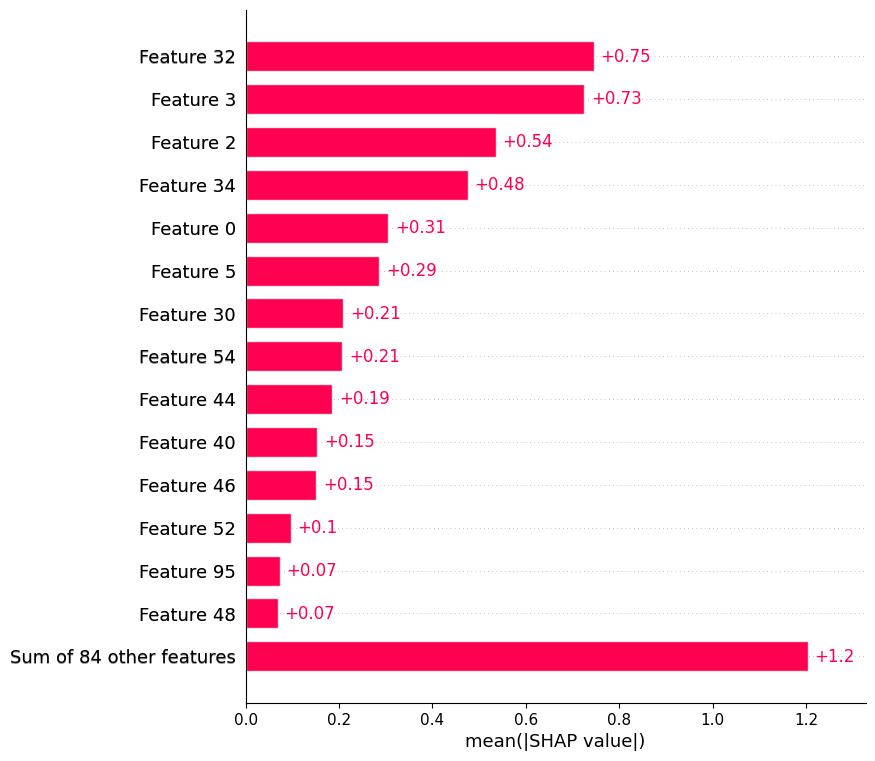

In [10]:
# ══════════════════════════════════════════════════════════════
# 10. EXPLICABILIDAD GLOBAL CON SHAP
# ══════════════════════════════════════════════════════════════

# Recupera por separado el preprocesamiento y el modelo ya entrenados
transformer = pipe.named_steps["prep"]                ### Bloque de transformación del pipeline
model = pipe.named_steps["model"]                     ### Clasificador lineal ajustado

# Obtiene los datos en el espacio que el modelo realmente observa
X_train_t = transformer.transform(X_train)            ### Entrenamiento transformado, usado como fondo de referencia
X_test_t = transformer.transform(X_test)              ### Prueba transformada, sobre la que se explica
feature_names = transformer.get_feature_names_out()   ### Nombres de las 98 columnas resultantes

# Submuestra de 500 personas para que el cálculo sea manejable
rng = np.random.default_rng(42)                       ### Generador con semilla fija para reproducir la muestra
sample_n = min(500, X_test_t.shape[0])                ### Tamaño de la muestra explicada
sample_pos = rng.choice(X_test_t.shape[0], size=sample_n, replace=False)  ### Posiciones elegidas sin reemplazo
X_shap = X_test_t[sample_pos]                         ### Subconjunto efectivamente explicado

# Explicador específico para modelos lineales
explainer = shap.LinearExplainer(model, X_train_t)    ### Calcula aportes exactos en la escala de log-odds
shap_values = explainer(X_shap)                       ### Valor SHAP de cada variable en cada predicción

print("Muestra SHAP:", X_shap.shape)                  ### Confirma el tamaño de la muestra y el número de columnas
shap.plots.bar(shap_values, max_display=15)           ### Importancia global: promedio del aporte absoluto por columna


### **Importancia global de las variables y equivalencia de columnas**

El gráfico identifica las columnas como `Feature 0`, `Feature 2`, `Feature 32` y así sucesivamente, en lugar de mostrar los nombres de las variables. La causa está en la celda anterior: `feature_names` se calcula mediante `transformer.get_feature_names_out()` pero no se transmite al explicador, de modo que SHAP numera las 98 columnas por su posición. La correspondencia es, sin embargo, completamente determinista, porque el `ColumnTransformer` ordena primero las seis variables numéricas y después las categorías de cada variable categórica en orden alfabético.

La verificación cierra de forma exacta: 6 numéricas + 8 de `workclass` + 16 de `education` + 7 de `marital-status` + 14 de `occupation` + 6 de `relationship` + 41 de `native-country` = **98 columnas**, que es la dimensión que imprime el propio notebook. El Ejercicio 4 confirma además cada valor de forma independiente al recuperar los nombres reales.

| Columna del gráfico | Variable transformada | mean\|SHAP\| | Variable original |
|---|---|---:|---|
| Feature 32 | `marital-status_Married-civ-spouse` | 0.7455 | marital-status |
| Feature 3 | `capital-gain` | 0.7250 | capital-gain |
| Feature 2 | `education-num` | 0.5364 | education-num |
| Feature 34 | `marital-status_Never-married` | 0.4765 | marital-status |
| Feature 0 | `age` | 0.3060 | age |
| Feature 5 | `hours-per-week` | 0.2865 | hours-per-week |
| Feature 30 | `marital-status_Divorced` | 0.2091 | marital-status |
| Feature 54 | `relationship_Own-child` | 0.2068 | relationship |
| Feature 44 | `occupation_Other-service` | 0.1860 | occupation |
| Feature 40 | `occupation_Exec-managerial` | 0.1535 | occupation |

| Indicador | Valor obtenido | Significado |
|---|---:|---|
| Columnas transformadas | 98 | 6 numéricas y 92 indicadoras one-hot |
| Personas explicadas | 500 | Submuestra con semilla fija |
| Columna de mayor aporte | `marital-status_Married-civ-spouse` | 0.7455 en log-odds |
| Escala de los valores | Log-odds | No son puntos porcentuales |
| Causa de los nombres numerados | `feature_names` no se pasa al explicador | Corregible pasando el argumento al `LinearExplainer` |
| Aporte residual | 84 columnas restantes suman 1.2 | Importancia muy dispersa en la cola |

> **Fragmentación del ranking.** Las variables categóricas aparecen partidas en una columna por categoría, de modo que este gráfico **subestima** su peso real. El Ejercicio 4 corrige esa distorsión agregando la importancia por variable de origen, y el resultado modifica sustancialmente el orden.

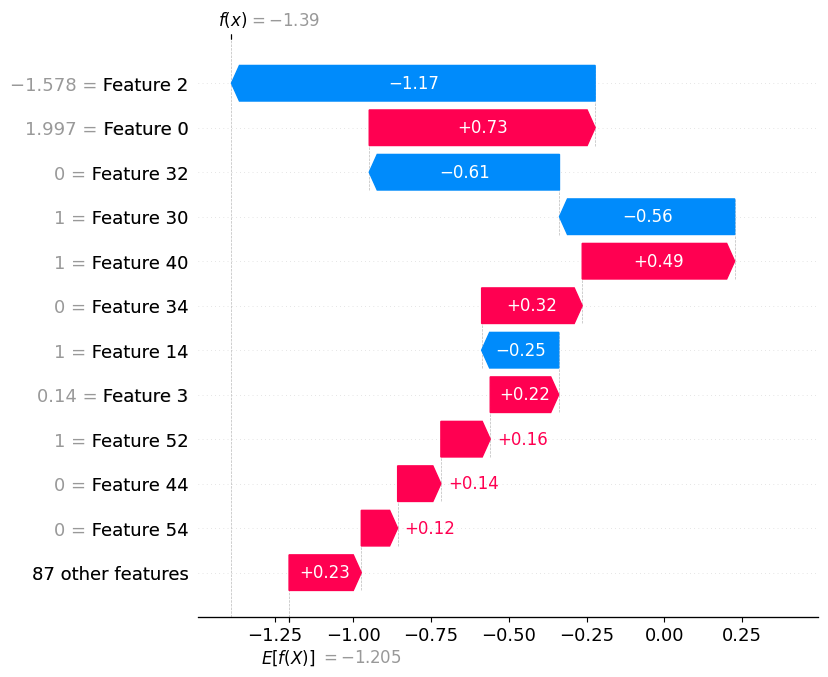

In [11]:
# ══════════════════════════════════════════════════════════════
# 11. EXPLICABILIDAD LOCAL DE UNA PREDICCIÓN INDIVIDUAL
# ══════════════════════════════════════════════════════════════

# Selección del caso que se explicará en detalle
case = 0                                              ### Primer registro de la muestra SHAP

# Gráfico en cascada: cómo cada variable desplaza la predicción desde el valor esperado
shap.plots.waterfall(shap_values[case], max_display=12)  ### Parte de E[f(X)] y acumula los aportes hasta f(x)


### **Descomposición de una predicción individual**

El gráfico en cascada explica el primer caso de la submuestra. El modelo parte del valor esperado **E[f(X)] = −1.205** y llega a **f(x) = −1.39** en escala de log-odds, lo que equivale a una probabilidad estimada de aproximadamente **19.9 %**: por debajo del umbral de 0,50, de modo que la persona queda clasificada como "ingreso igual o menor a 50 000 dólares".

Los aportes que **reducen** la probabilidad estimada suman más que los que la aumentan. El mayor es `education-num` con **−1.17**, asociado a un valor estandarizado de −1.578; que la columna `education_10th` valga 1 confirma la consistencia interna del caso, pues un nivel de décimo grado corresponde a `education-num = 6` y su estandarización reproduce exactamente ese −1.58. Le siguen `marital-status_Married-civ-spouse = 0` con **−0.61** y `marital-status_Divorced = 1` con **−0.56**.

Los aportes que **aumentan** la probabilidad están encabezados por `age` con **+0.73**, sobre un valor estandarizado de 1.997 que corresponde a una persona de edad avanzada, y por `occupation_Exec-managerial = 1` con **+0.49**.

| Variable transformada | Valor en el caso | Aporte (log-odds) | Dirección |
|---|---:|---:|---|
| `education-num` | −1.578 | **−1.17** | Reduce |
| `age` | 1.997 | **+0.73** | Aumenta |
| `marital-status_Married-civ-spouse` | 0 | −0.61 | Reduce |
| `marital-status_Divorced` | 1 | −0.56 | Reduce |
| `occupation_Exec-managerial` | 1 | +0.49 | Aumenta |
| `marital-status_Never-married` | 0 | +0.32 | Aumenta |
| `education_10th` | 1 | −0.25 | Reduce |
| `capital-gain` | 0.14 | +0.22 | Aumenta |
| `relationship_Not-in-family` | 1 | +0.16 | Aumenta |
| 87 columnas restantes | — | +0.23 | Aumenta |

| Indicador | Valor obtenido | Significado |
|---|---:|---|
| Valor esperado del modelo | −1.205 | Punto de partida de la descomposición |
| Predicción del caso | −1.39 | Resultado tras acumular los aportes |
| Probabilidad estimada | ≈ 19.9 % | Por debajo del umbral de 0,50 |
| Clasificación resultante | ≤ 50K | Clase negativa |
| Aporte individual mayor | `education-num`, −1.17 | Principal factor de reducción |
| Verificación de consistencia | `education_10th = 1` con `education-num` = −1.578 | Ambas columnas describen el mismo nivel educativo |

### **Pregunta 6**
¿Cuáles variables tienen mayor influencia global en las predicciones?

### **Variables con mayor influencia global en el modelo**

La respuesta depende de la unidad en que se mida la influencia, y las dos lecturas conducen a conclusiones distintas. Si se consideran las **columnas transformadas**, como muestra el gráfico del Paso 6, la de mayor aporte es `marital-status_Married-civ-spouse` con **0.7455**, seguida de `capital-gain` con **0.7250** y `education-num` con **0.5364**.

Esa lectura es engañosa porque fragmenta las variables categóricas: `marital-status` aparece repartida en siete columnas y `occupation` en catorce, de modo que su peso real queda disperso. Al agregar la importancia por **variable original**, como hace el Ejercicio 4, el orden cambia: **`marital-status` concentra el 28.94 %** de toda la importancia del modelo, seguida de `occupation` con 15.04 %, `capital-gain` con 13.36 %, `education-num` con 9.89 % y `relationship` con 8.56 %.

El hallazgo con consecuencias para la auditoría es que **`marital-status` y `relationship` suman en conjunto el 37.50 %** de la importancia total, y son precisamente las dos variables que el Ejercicio 1 identifica como proxy del sexo. La señal dominante del modelo es la misma información que reconstruye el atributo que se retiró del entrenamiento.

En el extremo opuesto, `fnlwgt` aporta apenas **0.63 %**. Es la variable menos influyente y, además, la única que carece de significado individual por ser un peso muestral del censo: no debería formar parte del modelo.

| Variable original | Columnas | Importancia | Participación |
|---|---:|---:|---:|
| `marital-status` | 7 | 1.5703 | **28.94 %** |
| `occupation` | 14 | 0.8162 | 15.04 % |
| `capital-gain` | 1 | 0.7250 | 13.36 % |
| `education-num` | 1 | 0.5364 | 9.89 % |
| `relationship` | 6 | 0.4647 | **8.56 %** |
| `age` | 1 | 0.3060 | 5.64 % |
| `hours-per-week` | 1 | 0.2865 | 5.28 % |
| `education` | 16 | 0.2344 | 4.32 % |
| `workclass` | 8 | 0.2141 | 3.95 % |
| `native-country` | 41 | 0.1880 | 3.46 % |
| `capital-loss` | 1 | 0.0501 | 0.92 % |
| `fnlwgt` | 1 | 0.0342 | 0.63 % |

> SHAP describe el comportamiento del modelo. Que `marital-status` concentre el 28.94 % significa que el clasificador se apoya en esa variable, **no** que el estado civil cause el nivel de ingreso.

### **Pregunta 7**
Elija una predicción y explique qué variables aumentaron o redujeron la probabilidad estimada. No use lenguaje causal.

### **Explicación local del primer caso de la muestra**

Para el primer caso de la submuestra, el modelo parte de un valor esperado de **−1.205** en escala de log-odds y llega a **−1.39**, equivalente a una probabilidad estimada de alrededor del **19.9 %**. Como el valor queda por debajo del umbral de 0,50, la persona es clasificada en la clase de ingreso igual o menor a 50 000 dólares.

**Variables asociadas a una reducción de la probabilidad estimada.** El mayor desplazamiento corresponde a `education-num`, con **−1.17**: el caso presenta un valor estandarizado de −1.578, y el modelo asigna una probabilidad estimada menor a los registros con ese perfil educativo. A continuación, el hecho de que `marital-status_Married-civ-spouse` valga 0 se asocia a **−0.61**, y que `marital-status_Divorced` valga 1 se asocia a **−0.56**. La columna `education_10th` aporta **−0.25** en la misma dirección.

**Variables asociadas a un aumento de la probabilidad estimada.** El principal es `age`, con **+0.73** sobre un valor estandarizado de 1.997. Le siguen `occupation_Exec-managerial = 1` con **+0.49**, el hecho de que `marital-status_Never-married` valga 0 con **+0.32**, `capital-gain` con **+0.22** y `relationship_Not-in-family = 1` con **+0.16**. Las 87 columnas restantes aportan en conjunto **+0.23**.

El saldo neto de estos desplazamientos es de −0.185 respecto del valor esperado, lo que sitúa la predicción por debajo del punto de partida del modelo.

| Variable transformada | Valor | Aporte | Asociación |
|---|---:|---:|---|
| `education-num` | −1.578 | −1.17 | Se asocia a una probabilidad estimada menor |
| `age` | 1.997 | +0.73 | Se asocia a una probabilidad estimada mayor |
| `marital-status_Married-civ-spouse` | 0 | −0.61 | Se asocia a una probabilidad estimada menor |
| `marital-status_Divorced` | 1 | −0.56 | Se asocia a una probabilidad estimada menor |
| `occupation_Exec-managerial` | 1 | +0.49 | Se asocia a una probabilidad estimada mayor |
| `marital-status_Never-married` | 0 | +0.32 | Se asocia a una probabilidad estimada mayor |
| `education_10th` | 1 | −0.25 | Se asocia a una probabilidad estimada menor |
| `capital-gain` | 0.14 | +0.22 | Se asocia a una probabilidad estimada mayor |
| `relationship_Not-in-family` | 1 | +0.16 | Se asocia a una probabilidad estimada mayor |

> **Precisión no causal.** Estas cifras describen cómo el modelo distribuye su predicción entre las variables que observa. No afirman que el nivel educativo o el estado civil **determinen** el ingreso de esta persona, ni que modificar una de esas variables cambiaría su ingreso real: solo indican que el modelo asigna probabilidades distintas a registros con perfiles distintos.

## **7. Checklist académico de gobierno y cumplimiento**

El checklist contrasta ocho controles de gobierno con la evidencia que el notebook puede efectivamente producir. Su valor está en la distinción entre lo que el código demuestra y lo que requiere una decisión organizacional: un control puede quedar sin evidencia no por descuido del analista, sino porque ningún script puede designar a un responsable ni definir un permiso de acceso.

El estado inicial registra lo que puede afirmarse **antes** de auditar. El Ejercicio 5 lo completa con la base normativa de cada control y con el estado final sustentado en la evidencia obtenida a lo largo del laboratorio.

Este instrumento es **académico** y no constituye certificación legal.

In [12]:
# ══════════════════════════════════════════════════════════════
# 12. CHECKLIST ACADÉMICO DE GOBIERNO Y CUMPLIMIENTO
# ══════════════════════════════════════════════════════════════

# Ocho controles de gobierno con su estado inicial y la evidencia disponible en el notebook
checklist = pd.DataFrame([
    ["Finalidad","¿Está documentado para qué se usará el modelo?","No evidenciado",""],
    ["Minimización","¿Cada variable tiene una justificación de necesidad?","No evidenciado",""],
    ["Calidad","¿Hay reglas y resultados de calidad de datos?","Parcial","El notebook muestra nulos y limpieza."],
    ["Linaje","¿Puede seguirse fuente→transformación→modelo→salida?","Parcial","Pipeline reproducible en notebook."],
    ["Acceso","¿Están definidos roles y permisos sobre datos/modelo?","No evidenciado",""],
    ["Transparencia","¿Se documentan lógica, limitaciones y supervisión?","Parcial","Completar informe ejecutivo."],
    ["Auditoría de subgrupos","¿Se revisaron errores y tasas por grupos?","Cumple","Ver tabla de auditoría."],
    ["Supervisión humana","¿Existe responsable para revisar decisiones de alto impacto?","No evidenciado",""],
], columns=["control","pregunta","estado_inicial","evidencia"])  ### Estado inicial: lo que se puede afirmar antes de auditar
display(checklist)                                    ### Presenta el punto de partida del cumplimiento


,control,pregunta,estado_inicial,evidencia
0,Finalidad,¿Está documentado para qué se usará el modelo?,No evidenciado,
1,Minimización,¿Cada variable tiene una justificación de nece...,No evidenciado,
2,Calidad,¿Hay reglas y resultados de calidad de datos?,Parcial,El notebook muestra nulos y limpieza.
3,Linaje,¿Puede seguirse fuente→transformación→modelo→s...,Parcial,Pipeline reproducible en notebook.
4,Acceso,¿Están definidos roles y permisos sobre datos/...,No evidenciado,
5,Transparencia,"¿Se documentan lógica, limitaciones y supervis...",Parcial,Completar informe ejecutivo.
6,Auditoría de subgrupos,¿Se revisaron errores y tasas por grupos?,Cumple,Ver tabla de auditoría.
7,Supervisión humana,¿Existe responsable para revisar decisiones de...,No evidenciado,


### **Punto de partida del cumplimiento**

De los ocho controles evaluados, el estado inicial registra **uno que cumple**, **tres parciales** y **cuatro sin evidencia**. El único control que cumple desde el inicio es la auditoría de subgrupos, porque es el que este laboratorio produce de forma directa.

El patrón que revela la tabla es más informativo que el conteo: los controles con alguna evidencia —Calidad, Linaje, Transparencia y Auditoría— son exactamente aquellos que un notebook puede sustentar, mientras que los cuatro sin evidencia —Finalidad, Minimización, Acceso y Supervisión humana— dependen de decisiones que se toman fuera del código. Esa frontera es el hallazgo del paso y la base de la Pregunta 8.

| Indicador | Valor obtenido | Significado |
|---|---:|---|
| Controles evaluados | 8 | Alcance del checklist académico |
| Estado inicial: Cumple | 1 | Auditoría de subgrupos |
| Estado inicial: Parcial | 3 | Calidad, Linaje y Transparencia |
| Estado inicial: No evidenciado | 4 | Finalidad, Minimización, Acceso y Supervisión humana |
| Controles sustentables por código | 4 de 8 | Límite de lo que el notebook puede demostrar |
| Naturaleza del instrumento | Académico | No constituye certificación legal |

Los estados posibles del checklist son **Cumple**, **Parcial**, **No evidenciado** y **No aplica**. El Ejercicio 5 asigna el estado final de cada control y lo vincula con su base normativa.

> Este checklist es **académico**. No constituye certificación legal.

### **Pregunta 8**
¿Qué control no puede demostrarse solo con código y necesita evidencia organizacional adicional?

### **Controles que exigen evidencia organizacional**

El control que de ningún modo puede demostrarse con código es la **supervisión humana**. Un script puede calcular que la FNR de las mujeres es de 0.2914 y producir la alerta correspondiente, pero no puede designar a la persona que la recibe, ni acreditar que esa persona tiene autoridad para detener una decisión, ni dejar constancia de que la revisó. La evidencia que lo sustenta es organizacional: una designación formal, un procedimiento de escalamiento y un registro firmado de las revisiones efectuadas.

El punto no es menor en el marco peruano. El Reglamento de la Ley N.° 31814, aprobado por **DS 115-2025-PCM**, exige **supervisión humana** en los sistemas de inteligencia artificial calificados como de riesgo alto. El control que ningún código puede acreditar es, justamente, el que la norma vuelve indispensable.

Junto a él hay otros dos en la misma condición. El **acceso** requiere una matriz de roles y permisos sobre datos y modelo, con su registro de concesiones y revocaciones; es un hecho administrativo. Y la **minimización** exige una justificación documentada de la necesidad de cada variable: el código puede medir que `fnlwgt` aporta apenas el 0.63 % de la importancia, pero quien debe declarar que esa variable es prescindible —o necesaria, y por qué— es el propietario del dato. La **finalidad** se encuentra en una situación intermedia: la ficha de gobierno declara la finalidad académica, pero la finalidad de negocio y el aprobador responsable son decisiones de la organización.

| Control | ¿Demostrable con código? | Evidencia organizacional requerida |
|---|---|---|
| **Supervisión humana** | **No** | Designación formal del responsable, procedimiento de escalamiento y registro de revisiones |
| **Acceso** | **No** | Matriz de roles y permisos con bitácora de concesiones |
| **Minimización** | Parcialmente | Justificación documentada de necesidad por variable, firmada por el propietario |
| Finalidad | Parcialmente | Finalidad de negocio y aprobador designado |
| Calidad | Sí | El código mide; falta el umbral de aceptación declarado |
| Linaje | Sí | Pipeline reproducible con semilla fija |
| Transparencia | Sí | SHAP documenta la lógica; falta el informe de limitaciones |
| Auditoría de subgrupos | Sí | Tablas de métricas y brechas producidas en este notebook |

| Indicador | Valor obtenido | Significado |
|---|---:|---|
| Control no demostrable por código | Supervisión humana | Requiere una persona designada, no un cálculo |
| Exigencia normativa asociada | DS 115-2025-PCM | Obligatoria en sistemas de riesgo alto |
| Controles que requieren evidencia externa | 3 de 8 | Minimización, Acceso y Supervisión humana |
| Evidencia que el código sí aporta | Calidad, Linaje, Transparencia, Auditoría | 4 de 8 controles |

## **8. Registro de hallazgos y plan de acción**

Un hallazgo que no tiene severidad, evidencia, acción, responsable y estado no es gestionable: es una observación. La estructura del registro obliga a convertir cada resultado de la auditoría en un compromiso verificable, con alguien que responde por él y un estado que permite seguirlo en el tiempo.

La celda de código define la estructura con una fila de referencia. La tabla que sigue la completa con los hallazgos efectivamente obtenidos en este laboratorio, cada uno trazado a la evidencia que lo sustenta.

In [13]:
# ══════════════════════════════════════════════════════════════
# 13. REGISTRO DE HALLAZGOS Y PLAN DE ACCIÓN
# ══════════════════════════════════════════════════════════════

# Estructura del registro: cada hallazgo requiere severidad, evidencia, acción, responsable y estado
hallazgos = pd.DataFrame(columns=[
    "hallazgo","severidad","evidencia","accion","responsable","estado"
])                                                    ### Un hallazgo sin responsable ni estado no es gestionable

# Fila de referencia que el estudiante reemplaza con los hallazgos de su propia auditoría
hallazgos.loc[0] = [
    "Ejemplo: brecha de FNR entre subgrupos",         ### Descripción del hallazgo
    "Por evaluar",                                    ### Severidad asignada tras el análisis
    "Tabla group_table / gap_df",                     ### Evidencia que lo sustenta
    "Revisar datos, umbral, variables proxy y proceso de supervisión",  ### Acción correctiva propuesta
    "Owner del modelo + negocio",                     ### Responsable de ejecutarla
    "Abierto"                                         ### Estado de seguimiento
]
display(hallazgos)                                    ### Presenta la estructura del registro


,hallazgo,severidad,evidencia,accion,responsable,estado
0,Ejemplo: brecha de FNR entre subgrupos,Por evaluar,Tabla group_table / gap_df,"Revisar datos, umbral, variables proxy y proce...",Owner del modelo + negocio,Abierto


### **Registro de hallazgos de la auditoría**

Se registran cinco hallazgos, ordenados por severidad. La severidad se asigna combinando la magnitud de la brecha, el tamaño del grupo afectado y el tipo de error, con el criterio establecido en la Pregunta 5: los falsos negativos tienen prioridad sobre los falsos positivos porque su costo recae sobre la persona y no sobre la organización.

| # | Hallazgo | Severidad | Evidencia | Acción | Responsable | Estado |
|---|---|---|---|---|---|---|
| 1 | `relationship` reconstruye el sexo de forma casi determinista: Husband 99.99 % masculino y Wife 99.87 % femenino, con cobertura del 45.14 % de la población | **Alta** | Ejercicio 1, tabla cruzada normalizada | Evaluar la exclusión o recodificación de `relationship`; medir el efecto sobre la brecha de FNR | Propietario del modelo + legal | Abierto |
| 2 | Brecha de FNR por sexo de 0.1464 (Female 0.2914 frente a Male 0.1450), razón 2.01×, sobre 4 057 mujeres y ≈ 132 omisiones | **Alta** | `group_table`, `gap_df` | Revisar umbral por grupo, rebalanceo y variables proxy; fijar un límite tolerable de brecha | Propietario del modelo + negocio | Abierto |
| 3 | Supervisión humana sin evidencia, siendo control indispensable bajo DS 115-2025-PCM para sistemas de riesgo alto | **Alta** | Checklist, Ejercicio 5 | Designar responsable formal, procedimiento de escalamiento y registro de revisiones | Comité de gobierno de datos | Abierto |
| 4 | Brecha de FNR por grupo de edad de 0.1546 (17-29: 0.2865 frente a 50+: 0.1319) sobre 3 663 personas jóvenes | **Media** | Ejercicio 3 | Incorporar la edad como dimensión permanente de auditoría | Propietario del modelo | Abierto |
| 5 | `fnlwgt`, peso muestral del censo sin significado individual, forma parte del modelo con 0.63 % de importancia | **Media** | Ejercicio 4 | Retirar la variable o documentar su necesidad; control de minimización | Propietario de datos | Abierto |

| Indicador | Valor obtenido | Significado |
|---|---:|---|
| Hallazgos registrados | 5 | Resultado consolidado de la auditoría |
| Severidad alta | 3 | Proxy, brecha de FNR por sexo y supervisión humana |
| Severidad media | 2 | Brecha por edad y variable sin significado individual |
| Hallazgos con responsable asignado | 5 de 5 | Condición para que el registro sea gestionable |
| Hallazgos cerrados | 0 | Ninguna acción ejecutada a la fecha |

### **Pregunta 9**
¿Qué hallazgo impediría desplegar el modelo hasta ser resuelto?

### **Hallazgo bloqueante para el despliegue**

El hallazgo que impide el despliegue es la **combinación del proxy con la brecha de falsos negativos por sexo**. Ninguno de los dos basta por separado; juntos eliminan la defensa del modelo.

La exclusión de `sex` del entrenamiento es el argumento con el que un modelo se presenta como neutral respecto del sexo. El Ejercicio 1 demuestra que ese argumento no se sostiene: la variable `relationship`, que el modelo **sí** recibe, reconstruye el sexo con una concentración del **99.99 %** en la categoría Husband y del **99.87 %** en Wife, alcanzando al **45.14 %** de la población. El Ejercicio 4 agrava el cuadro al mostrar que `marital-status` y `relationship` concentran el **37.50 %** de toda la importancia del modelo: la señal dominante del clasificador es precisamente la que codifica el atributo retirado.

Si esa reconstrucción no produjera un trato desigual, el problema sería teórico. Pero sí lo produce: la FNR es de **0.2914 en mujeres frente a 0.1450 en hombres**, una razón de **2.01**, sobre un grupo de **4 057 personas**. El modelo no puede afirmar que es ciego al sexo, y su comportamiento medido es desigual en el tipo de error más costoso para la persona afectada.

A este bloqueo técnico se suma uno **normativo**: el control de supervisión humana permanece sin evidencia, y el DS 115-2025-PCM lo exige para sistemas de riesgo alto. Mientras no exista un responsable designado, el modelo no puede desplegarse aunque la brecha se corrigiera.

| Condición de bloqueo | Evidencia | Valor |
|---|---|---:|
| El proxy anula la exclusión de `sex` | `relationship`: Husband masculino | 99.99 % |
| | `relationship`: Wife femenina | 99.87 % |
| | Población cubierta por categorías proxy | 45.14 % |
| El proxy domina el modelo | `marital-status` + `relationship` en importancia SHAP | 37.50 % |
| La desigualdad se materializa | FNR Female frente a FNR Male | 0.2914 / 0.1450 |
| | Razón entre tasas | 2.01× |
| | Personas en el grupo afectado | 4 057 |
| Falta el control exigido por norma | Supervisión humana | No evidenciado |

**Condición de levantamiento.** El bloqueo puede levantarse cuando se cumplan tres requisitos simultáneos: que la brecha de FNR por sexo descienda por debajo de un límite declarado y aprobado por el comité; que se documente el efecto de excluir o recodificar `relationship`; y que exista un responsable formalmente designado para la supervisión humana. Hasta entonces, la recomendación es **no aprobar todavía**.

### **Pregunta 10**
¿Qué evidencia conservaría para demostrar que el modelo fue auditado y revisado antes de su uso?

### **Evidencia a conservar como expediente de auditoría**

La pregunta que debe poder responderse meses después no es "¿el modelo era bueno?" sino "¿qué se sabía, quién lo sabía y qué decidió?". La evidencia debe permitir **reconstruir el estado del conocimiento en la fecha de la decisión**, y por eso cada pieza necesita fecha y responsable identificable.

Nueve elementos componen ese expediente. El **conjunto de datos versionado** con su identificador de fuente y una huella digital que permita verificar que nadie lo alteró. El **notebook ejecutado** con todas las semillas fijas, que es lo que hace reproducible el resultado. Las **tablas de métricas por subgrupo y de brechas** con fecha, que son la fotografía del comportamiento auditado. Las **explicaciones SHAP** global y local, que documentan la lógica del modelo. El **checklist de gobierno** con base normativa y estado final. El **registro de hallazgos** con severidad, responsable y estado. El **umbral de decisión** con la constancia de quién lo eligió y con qué criterio, porque redistribuye el daño entre grupos y no es una decisión técnica. El **acta de decisión** firmada, que indique si se aprueba, se aprueba con condiciones o no se aprueba. Y el **registro de supervisión humana** posterior, que acredite quién revisa las decisiones de alto impacto.

| Evidencia | Qué demuestra | Dónde se origina |
|---|---|---|
| Conjunto versionado con huella digital | Que los datos auditados son los mismos que se usaron | Fuente UCI ID 2 |
| Notebook ejecutado con semillas fijas | Reproducibilidad del resultado por un tercero | `random_state=42` en partición, modelo y muestra SHAP |
| `group_table` y `gap_df` fechadas | Comportamiento medido por subgrupo en esa fecha | Pasos 4 y 5 |
| Explicaciones SHAP global y local | Lógica del modelo documentada | Paso 6 y Ejercicio 4 |
| Checklist con base normativa y estado final | Cobertura de cumplimiento declarada | Paso 7 y Ejercicio 5 |
| Registro de hallazgos | Qué se detectó y quién responde por ello | Paso 8 |
| Umbral elegido y su justificación | Quién decidió el reparto del error | Ejercicio 2 |
| Acta de decisión firmada | Si se aprobó, con qué condiciones y quién lo aprobó | Comité de gobierno |
| Registro de supervisión humana | Que las decisiones de alto impacto se revisan | Proceso operativo |

| Indicador | Valor obtenido | Significado |
|---|---:|---|
| Elementos del expediente | 9 | Cobertura mínima para una auditoría verificable |
| Elementos que este notebook ya produce | 5 | Datos, notebook, métricas, SHAP y checklist |
| Elementos de origen organizacional | 4 | Umbral decidido, acta, hallazgos gestionados y supervisión |
| Criterio común | Fecha y responsable identificables | Sin ellos la evidencia no es auditable |

## **9. Informe ejecutivo de auditoría**

Respuesta en términos de negocio, con las cifras del notebook, en un máximo de doce líneas en total.

**A. Describa el desempeño global del modelo y dos métricas por subgrupo que matizan ese resultado.**

**Respuesta:** El modelo alcanza 80.12 % de exactitud y 83.23 % de recall sobre 12 211 personas, apenas cuatro puntos por encima del 76.07 % que lograría predecir siempre la clase mayoritaria. Dos cifras por subgrupo matizan ese resultado: la FNR de las mujeres es de 29.14 % frente a 14.50 % en hombres, y la de las personas negras es de 26.39 % frente a 16.09 % en blancas.

**B. Identifique la principal brecha, indique el tamaño de los grupos involucrados y el tipo de error.**

**Respuesta:** La principal brecha accionable es la de falsos negativos por sexo: 14.64 puntos, con una razón de 2.01 veces, sobre 4 057 mujeres frente a 8 154 hombres. El error es de omisión: se niega a la persona lo que le corresponde, y su costo recae sobre ella, no sobre la organización.

**C. Presente una explicación SHAP global y una local, sin lenguaje causal.**

**Respuesta:** En conjunto, el modelo se apoya sobre todo en `marital-status` (28.94 % de la importancia), `occupation` (15.04 %) y `capital-gain` (13.36 %). En el caso individual revisado, la probabilidad estimada baja de −1.205 a −1.39 en log-odds (≈ 19.9 %): `education-num` se asocia al mayor descenso (−1.17) y `age` al mayor aumento (+0.73). Son asociaciones del modelo, no relaciones causales.

**D. Señale dos controles de gobierno revisados y una evidencia de cumplimiento faltante.**

**Respuesta:** Se revisaron Auditoría de subgrupos, que cumple con tablas de métricas y brechas por sexo, raza y edad, y Linaje, que cumple con un pipeline reproducible de semilla fija. Falta la evidencia de Supervisión humana: no existe un responsable designado para revisar las decisiones de alto impacto.

**E. Indique una limitación y su recomendación: aprobar, aprobar con condiciones o no aprobar todavía.**

**Respuesta:** La limitación principal es que retirar `sex` no elimina la información: `relationship` la reconstruye al 99.99 % en Husband y al 99.87 % en Wife, cubriendo al 45.14 % de la población. Recomendación: **no aprobar todavía**, hasta que la brecha de FNR por sexo baje de un límite aprobado por el comité y exista responsable designado para la supervisión humana.

## **10. Reto de aplicación**

Los cinco ejercicios operan sobre los objetos ya construidos: `X_model`, `audit`, `audit_result`, `proba`, `shap_values` y `checklist`. Cada uno reutiliza las funciones definidas en los pasos anteriores —`group_metrics` y `gap_report`— en lugar de recalcular las métricas por separado: así los números de los ejercicios son directamente comparables con los de la auditoría base y se evita que ambas secciones se desincronicen.

Los ejercicios siguen una progresión deliberada. El primero pone a prueba el supuesto de la sección 2; el segundo examina el umbral como decisión de negocio; el tercero amplía la auditoría a una dimensión no prevista; el cuarto corrige la distorsión del gráfico SHAP; y el quinto cierra el cumplimiento con base normativa.

In [14]:
# ══════════════════════════════════════════════════════════════
# 14. VERIFICACIÓN DE LOS OBJETOS DE TRABAJO DE LOS RETOS
# ══════════════════════════════════════════════════════════════

# Confirma que los tres objetos que usan los cinco ejercicios están disponibles y con la forma esperada
print("Variables del modelo:", X_model.shape)         ### Conjunto completo sin las variables sensibles
print("Auditoría de prueba:", audit_result.shape)     ### Tabla de auditoría con etiquetas y predicciones
print("Valores SHAP:", shap_values.values.shape)      ### Muestra explicada por columnas transformadas


Variables del modelo: (48842, 12)
Auditoría de prueba: (12211, 5)
Valores SHAP: (500, 98)


### **Verificación de los objetos de trabajo**

Los tres objetos requeridos están disponibles con la forma esperada: `X_model` con **48 842 filas y 12 variables**, `audit_result` con **12 211 filas y 5 columnas** y `shap_values` con **500 casos explicados sobre 98 columnas transformadas**.

La verificación no es un trámite. `X_model` conserva las 48 842 filas porque la exclusión retiró columnas y no registros; `audit_result` tiene solo 12 211 porque la auditoría se restringe a la muestra de prueba, que es la condición para que las métricas no estén contaminadas por datos que el modelo ya vio; y las 98 columnas de `shap_values` confirman la expansión one-hot que el Ejercicio 4 deberá revertir.

| Objeto | Forma | Significado |
|---|---:|---|
| `X_model` | 48 842 × 12 | Conjunto completo sin `sex` ni `race` |
| `audit_result` | 12 211 × 5 | Solo la muestra de prueba, con etiqueta y predicción |
| `shap_values` | 500 × 98 | Submuestra explicada por columnas transformadas |

## **Ejercicio 1 — Detección de variables proxy del sexo**
En el Paso 3 se excluyó la variable `sex` del entrenamiento. Sin embargo, una exclusión solo es efectiva si ninguna otra variable reproduce la información retirada. En este ejercicio deberá comprobar numéricamente si `relationship` y `marital-status`, que el modelo sí recibe, permiten reconstruir el sexo de las personas.

**Se solicita:**
- Construir una tabla cruzada entre `relationship` y el sexo de la tabla de auditoría, normalizada por fila.
- Construir la misma tabla para `marital-status`.
- Identificar las categorías en que un solo sexo supera el 85 % de los casos.

**Enfoque.** La normalización se hace **por fila** y no por columna: por fila la tabla responde "dado que una persona pertenece a esta categoría, ¿qué sexo tiene?", que es exactamente la pregunta de reconstrucción; por columna respondería lo contrario y no serviría para detectar un proxy. Se añaden dos indicadores que la consigna no pide pero que son necesarios para interpretar el resultado: el tamaño `n` de cada categoría, porque una categoría de 30 personas al 100 % no constituye un proxy operativo, y la **cobertura**, es decir, qué proporción de la población total queda identificable. El umbral del 85 % se declara antes de observar los resultados.

In [15]:
# ══════════════════════════════════════════════════════════════
# EJERCICIO 1. DETECCIÓN DE VARIABLES PROXY DEL SEXO
# ══════════════════════════════════════════════════════════════

# Regla declarada antes de mirar los resultados: una categoría es proxy si un solo sexo la domina
UMBRAL_PROXY = 0.85                                   ### Umbral de concentración fijado por decisión analítica

# Reúne las dos variables candidatas junto al sexo retirado del entrenamiento
proxy_df = pd.DataFrame({
    "relationship":   X_model["relationship"],        ### Variable que el modelo SÍ recibe
    "marital-status": X_model["marital-status"],      ### Variable que el modelo SÍ recibe
    "sex":            audit["sex"]                    ### Variable retirada, conservada solo para auditar
})                                                    ### La unión es por índice, no por posición

# Construye la tabla cruzada normalizada por fila y mide la concentración de cada categoría
def tabla_proxy(variable, umbral=UMBRAL_PROXY):
    cruce = pd.crosstab(proxy_df[variable], proxy_df["sex"], normalize="index")  ### Proporción de cada sexo DENTRO de la categoría
    resumen = pd.DataFrame({
        "n":              proxy_df[variable].value_counts(),   ### Tamaño de la categoría
        "sexo_dominante": cruce.idxmax(axis=1),                ### Sexo mayoritario
        "concentracion":  cruce.max(axis=1)                    ### Proporción del sexo mayoritario
    })
    resumen["es_proxy"] = resumen.concentracion >= umbral      ### Marca si supera el umbral declarado
    return cruce.round(4), resumen.sort_values("concentracion", ascending=False).round(4)

# Aplica el procedimiento a cada variable candidata
for var in ["relationship", "marital-status"]:
    cruce, resumen = tabla_proxy(var)

    print(f"\n── Tabla cruzada normalizada por fila: {var} × sex ──")
    display(cruce)

    print(f"── Concentración por categoría: {var} ──")
    display(resumen)

    # Mide qué parte de la población queda cubierta por categorías proxy
    cobertura = resumen.loc[resumen.es_proxy, "n"].sum() / len(proxy_df)   ### Impacto real, no solo cuántas categorías
    print(f"Categorías proxy (≥{UMBRAL_PROXY:.0%}): {resumen.es_proxy.sum()} de {len(resumen)}")
    print(f"Población cubierta por categorías proxy: {cobertura:.2%}")



── Tabla cruzada normalizada por fila: relationship × sex ──


sex,Female,Male
relationship,,
Husband,0.0001,0.9999
Not-in-family,0.4665,0.5335
Other-relative,0.4575,0.5425
Own-child,0.4453,0.5547
Unmarried,0.7664,0.2336
Wife,0.9987,0.0013


── Concentración por categoría: relationship ──


,n,sexo_dominante,concentracion,es_proxy
relationship,,,,
Husband,19716,Male,0.9999,True
Wife,2331,Female,0.9987,True
Unmarried,5125,Female,0.7664,False
Own-child,7581,Male,0.5547,False
Other-relative,1506,Male,0.5425,False
Not-in-family,12583,Male,0.5335,False


Categorías proxy (≥85%): 2 de 6
Población cubierta por categorías proxy: 45.14%

── Tabla cruzada normalizada por fila: marital-status × sex ──


sex,Female,Male
marital-status,,
Divorced,0.6032,0.3968
Married-AF-spouse,0.6757,0.3243
Married-civ-spouse,0.1108,0.8892
Married-spouse-absent,0.4841,0.5159
Never-married,0.4479,0.5521
Separated,0.6085,0.3915
Widowed,0.8123,0.1877


── Concentración por categoría: marital-status ──


,n,sexo_dominante,concentracion,es_proxy
marital-status,,,,
Married-civ-spouse,22379,Male,0.8892,True
Widowed,1518,Female,0.8123,False
Married-AF-spouse,37,Female,0.6757,False
Separated,1530,Female,0.6085,False
Divorced,6633,Female,0.6032,False
Never-married,16117,Male,0.5521,False
Married-spouse-absent,628,Male,0.5159,False


Categorías proxy (≥85%): 1 de 7
Población cubierta por categorías proxy: 45.82%


### **Capacidad de reconstrucción del sexo a partir de variables del modelo**

El resultado es concluyente y desfavorable para el supuesto de la sección 2. En la variable **`relationship`**, dos de las seis categorías superan ampliamente el umbral declarado: **`Husband` es 99.99 % masculina** sobre 19 716 personas y **`Wife` es 99.87 % femenina** sobre 2 331. No se trata de una asociación estadística fuerte sino de una correspondencia prácticamente determinista: conociendo únicamente esas dos categorías, el sexo de **45.14 %** de la población queda reconstruido.

En **`marital-status`** el efecto existe pero es menor: una sola categoría de siete supera el umbral, `Married-civ-spouse` con **88.92 %** masculino sobre 22 379 personas, con una cobertura de **45.82 %**. La segunda más concentrada, `Widowed` con 81.23 % femenino, queda por debajo del corte.

La diferencia entre ambas variables importa. `marital-status` refleja una asociación social —la mayoría de los matrimonios civiles registrados declara al varón como titular—, mientras que `relationship` codifica el rol dentro del hogar con etiquetas que **ya contienen el género en su propia definición**: "Husband" y "Wife" no son categorías neutras que resulten estar correlacionadas con el sexo, son el sexo expresado con otro nombre. Retirar `sex` y conservar `relationship` equivale a retirar una etiqueta y mantener su sinónimo.

| Variable | Categoría | n | Sexo dominante | Concentración | ¿Proxy? |
|---|---|---:|---|---:|---|
| `relationship` | Husband | 19 716 | Male | **0.9999** | **Sí** |
| `relationship` | Wife | 2 331 | Female | **0.9987** | **Sí** |
| `relationship` | Unmarried | 5 125 | Female | 0.7664 | No |
| `relationship` | Own-child | 7 581 | Male | 0.5547 | No |
| `relationship` | Other-relative | 1 506 | Male | 0.5425 | No |
| `relationship` | Not-in-family | 12 583 | Male | 0.5335 | No |
| `marital-status` | Married-civ-spouse | 22 379 | Male | **0.8892** | **Sí** |
| `marital-status` | Widowed | 1 518 | Female | 0.8123 | No |
| `marital-status` | Married-AF-spouse | 37 | Female | 0.6757 | No |
| `marital-status` | Separated | 1 530 | Female | 0.6085 | No |
| `marital-status` | Divorced | 6 633 | Female | 0.6032 | No |
| `marital-status` | Never-married | 16 117 | Male | 0.5521 | No |
| `marital-status` | Married-spouse-absent | 628 | Male | 0.5159 | No |

| Indicador | Valor obtenido | Significado |
|---|---:|---|
| Umbral declarado | 85 % | Fijado antes de observar los resultados |
| Categorías proxy en `relationship` | 2 de 6 | Husband y Wife |
| Cobertura de `relationship` | **45.14 %** | Proporción de la población identificable |
| Categorías proxy en `marital-status` | 1 de 7 | Married-civ-spouse |
| Cobertura de `marital-status` | 45.82 % | Proporción de la población identificable |
| Concentración máxima observada | 0.9999 | Reconstrucción prácticamente determinista |

**Pregunta 11.** ¿Qué variable funciona como proxy más fuerte del sexo y qué implica para la decisión de excluir `sex` del modelo?

### **Identificación del proxy dominante y su consecuencia**

El proxy más fuerte es **`relationship`**, y la distancia con la segunda candidata no es estrecha. Sus dos categorías principales alcanzan concentraciones de **99.99 %** y **99.87 %**, frente al máximo de **88.92 %** de `marital-status`. En términos de error de reconstrucción, `relationship` se equivoca en aproximadamente **1 de cada 10 000 casos** dentro de esas categorías, mientras que `marital-status` se equivoca en **11 de cada 100**. Son dos órdenes de magnitud de diferencia: la primera es una reconstrucción, la segunda una correlación.

La implicación para la decisión de excluir `sex` es directa: **la exclusión es cosmética**. El modelo no recibe la columna `sex`, pero recibe `relationship`, que la contiene bajo otro nombre para el 45.14 % de la población. Por eso la brecha no desapareció al excluir la variable: la FNR de las mujeres sigue siendo de 0.2914 frente a 0.1450 en hombres.

El agravante lo aporta el Ejercicio 4: `marital-status` y `relationship` concentran juntas el **37.50 %** de la importancia total del modelo. No son variables periféricas que arrastren el sexo de forma accidental; son la señal dominante del clasificador.

Hay una consecuencia práctica que conviene nombrar. La respuesta correcta **no** es eliminar `relationship` de forma automática: es una variable con contenido económico legítimo, pues la posición en el hogar se asocia a la trayectoria laboral. La respuesta correcta es **medir** el efecto de excluirla o recodificarla a categorías neutras —por ejemplo, agrupando "Husband" y "Wife" en "Cónyuge"— y comparar la brecha de FNR antes y después. Sin esa medición, cualquier afirmación sobre la neutralidad del modelo carece de respaldo.

| Criterio | `relationship` | `marital-status` |
|---|---:|---:|
| Concentración máxima | **0.9999** (Husband) | 0.8892 (Married-civ-spouse) |
| Segunda concentración | **0.9987** (Wife) | 0.8123 (Widowed) |
| Error de reconstrucción | ≈ 1 en 10 000 | ≈ 11 en 100 |
| Categorías sobre el umbral | 2 de 6 | 1 de 7 |
| Cobertura poblacional | 45.14 % | 45.82 % |
| Naturaleza de la relación | El género está en la definición de la categoría | Asociación social |
| Importancia SHAP de la variable | 8.56 % | 28.94 % |

## **Ejercicio 2 — Efecto del umbral de decisión sobre las brechas**
El modelo base clasifica como positivo a quien supera una probabilidad de 0,50. Ese umbral no es un dato técnico neutral, sino una decisión de negocio que redistribuye los errores entre los grupos. Corresponde medir cómo cambian las brechas por sexo al mover el umbral.

**Se solicita:**
- Recalcular las predicciones con umbrales de 0,30, 0,50 y 0,70.
- Obtener, para cada umbral, el FNR y el FPR de mujeres y de hombres con la función `group_metrics`.
- Construir las columnas `brecha_fnr` y `brecha_fpr` y presentar los resultados en una tabla.

**Enfoque.** Las brechas se calculan **con signo**, definidas como mujeres menos hombres, y no en valor absoluto como hace `gap_report` en el Paso 5. La diferencia es sustantiva: el valor absoluto informa la magnitud pero oculta **a quién perjudica cada error**, que es justamente lo que la Pregunta 12 necesita saber. Se reutiliza `group_metrics` en lugar de recalcular las tasas a mano, para que las cifras de este ejercicio sean directamente comparables con las del Paso 4. Solo cambia el punto de corte: el modelo y las probabilidades estimadas son los mismos en los tres escenarios.

In [16]:
# ══════════════════════════════════════════════════════════════
# EJERCICIO 2. EFECTO DEL UMBRAL DE DECISIÓN SOBRE LAS BRECHAS
# ══════════════════════════════════════════════════════════════

# Umbrales evaluados: el 0,50 del modelo base y dos alternativas
UMBRALES = [0.30, 0.50, 0.70]                         ### El umbral es una decisión de negocio, no un parámetro técnico

filas = []                                            ### Almacena el resultado de cada escenario

for u in UMBRALES:

    # Reclasifica con el umbral evaluado; la probabilidad no cambia, solo el punto de corte
    pred_u = (proba >= u).astype(int)                 ### Mismo modelo, distinta frontera de decisión

    # Reconstruye la tabla de auditoría con la nueva predicción
    audit_u = audit_test.copy()                       ### Solo personas de la muestra de prueba
    audit_u["y_true"] = y_test                        ### Valor real observado
    audit_u["y_pred"] = pred_u                        ### Predicción con el umbral evaluado
    audit_u["proba"]  = proba                         ### Probabilidad estimada, invariable

    # Métricas por sexo con la MISMA función del Paso 4, para que los números sean comparables
    gm_u = group_metrics(audit_u, "sex").set_index("group")

    # Extrae los dos tipos de error de cada grupo
    fnr_f, fnr_m = gm_u.loc["Female", "fnr"], gm_u.loc["Male", "fnr"]    ### Falsos negativos: a quién se le niega lo que le corresponde
    fpr_f, fpr_m = gm_u.loc["Female", "fpr"], gm_u.loc["Male", "fpr"]    ### Falsos positivos: a quién se le concede sin corresponder

    # Registra el escenario; la brecha se define como Mujeres menos Hombres para conservar el signo
    filas.append({
        "umbral":      u,
        "fnr_female":  fnr_f, "fnr_male": fnr_m, "brecha_fnr": fnr_f - fnr_m,
        "fpr_female":  fpr_f, "fpr_male": fpr_m, "brecha_fpr": fpr_f - fpr_m,
        "tasa_positiva_global": pred_u.mean(),                            ### Cuántos positivos produce el umbral
        "recall_global":        recall_score(y_test, pred_u, zero_division=0)
    })

# Consolida y presenta los tres escenarios
umbral_table = pd.DataFrame(filas)
display(umbral_table.round(4))

# Resume la dirección de cada brecha en cada escenario
print("\n── Dirección de las brechas (signo = a quién perjudica) ──")
for _, r in umbral_table.iterrows():
    print(f"Umbral {r.umbral:.2f} · FNR {'perjudica a mujeres' if r.brecha_fnr > 0 else 'perjudica a hombres'} "
          f"({r.brecha_fnr:+.4f}) · FPR {'perjudica a mujeres' if r.brecha_fpr > 0 else 'perjudica a hombres'} "
          f"({r.brecha_fpr:+.4f})")


,umbral,fnr_female,fnr_male,brecha_fnr,fpr_female,fpr_male,brecha_fpr,tasa_positiva_global,recall_global
0,0.3,0.1545,0.0502,0.1043,0.1615,0.4355,-0.2740,0.4738,0.9336
1,0.5,0.2914,0.1450,0.1464,0.0844,0.2872,-0.2029,0.3578,0.8323
2,0.7,0.4371,0.3196,0.1175,0.0366,0.1321,-0.0955,0.2308,0.6622



── Dirección de las brechas (signo = a quién perjudica) ──
Umbral 0.30 · FNR perjudica a mujeres (+0.1043) · FPR perjudica a hombres (-0.2740)
Umbral 0.50 · FNR perjudica a mujeres (+0.1464) · FPR perjudica a hombres (-0.2029)
Umbral 0.70 · FNR perjudica a mujeres (+0.1175) · FPR perjudica a hombres (-0.0955)


### **Redistribución del error entre grupos según el umbral**

El resultado central es que **las dos brechas apuntan en direcciones opuestas en los tres umbrales**, sin excepción. La brecha de FNR es positiva siempre, es decir, las mujeres son omitidas con mayor frecuencia en todos los escenarios. La brecha de FPR es negativa siempre, es decir, los hombres reciben señales infundadas con mayor frecuencia en todos los escenarios. No existe un punto de corte en el que ambas se anulen.

El comportamiento de cada brecha al mover el umbral es además distinto. La de **FPR decrece de forma monótona**: pasa de −0.2740 en 0,30 a −0.2029 en 0,50 y a −0.0955 en 0,70; subir el umbral la reduce de manera sostenida. La de **FNR no es monótona**: vale 0.1043 en 0,30, alcanza su máximo de **0.1464 justamente en el umbral actual de 0,50** y baja a 0.1175 en 0,70. El umbral que el modelo usa hoy es, de los tres evaluados, el que produce la **mayor** brecha de omisión entre sexos.

El costo global del movimiento también es visible. Bajar a 0,30 eleva el recall global a 93.36 % pero clasifica como positivo al 47.38 % de la muestra; subir a 0,70 reduce el recall a 66.22 % y deja al 23.08 % de positivos. Cada elección reparte de otro modo el daño: no hay una opción que domine a las demás.

| Umbral | FNR mujeres | FNR hombres | Brecha FNR | FPR mujeres | FPR hombres | Brecha FPR | Tasa positiva | Recall global |
|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 0,30 | 0.1545 | 0.0502 | **+0.1043** | 0.1615 | 0.4355 | **−0.2740** | 0.4738 | 0.9336 |
| 0,50 | 0.2914 | 0.1450 | **+0.1464** | 0.0844 | 0.2872 | **−0.2029** | 0.3578 | 0.8323 |
| 0,70 | 0.4371 | 0.3196 | **+0.1175** | 0.0366 | 0.1321 | **−0.0955** | 0.2308 | 0.6622 |

| Indicador | Valor obtenido | Significado |
|---|---:|---|
| Dirección de la brecha de FNR | Positiva en los tres umbrales | Perjudica a las mujeres siempre |
| Dirección de la brecha de FPR | Negativa en los tres umbrales | Perjudica a los hombres siempre |
| Umbral que minimiza la brecha de FNR | 0,30 (+0.1043) | Menor desigualdad de omisión |
| Umbral que minimiza la brecha de FPR | 0,70 (−0.0955) | Menor desigualdad de señal infundada |
| Umbral que maximiza la brecha de FNR | **0,50 (+0.1464)** | Es el umbral actualmente en uso |
| Umbral que anula ambas brechas | **No existe entre los evaluados** | El conflicto es estructural |

**Pregunta 12.** ¿Existe un umbral que elimine a la vez las brechas de FNR y de FPR? ¿Quién debería decidir el umbral final?

### **Imposibilidad de un umbral neutral y responsabilidad de la decisión**

**No existe, y el motivo no es que falte explorar más valores.** Las dos brechas tienen signo opuesto en los tres umbrales evaluados: la de FNR es positiva siempre y la de FPR negativa siempre. Mover el umbral desplaza predicciones de una clase a la otra, de modo que reducir una brecha de omisión implica aumentar la de señal infundada. Bajar el corte a 0,30 reduce la brecha de FNR a 0.1043 pero lleva la de FPR a −0.2740; subirlo a 0,70 reduce la de FPR a −0.0955 pero la de FNR vuelve a subir a 0.1175. El conflicto es estructural: con prevalencias distintas entre grupos —11.17 % en mujeres frente a 30.29 % en hombres— un umbral único no puede igualar ambas tasas de error simultáneamente.

La observación más incómoda es que el umbral vigente, 0,50, es de los tres el que produce la **mayor** brecha de omisión. Fue heredado por convención, no elegido por análisis.

**Quién debe decidirlo.** No el equipo de datos por sí solo. Elegir el umbral es elegir **quién asume el error**, y esa es una decisión de política institucional con consecuencias jurídicas. El equipo de datos aporta la tabla de escenarios y explica el intercambio; quien decide debe ser el **responsable del proceso de negocio junto con el comité de gobierno de datos y el área legal**, porque el DS 115-2025-PCM exige supervisión humana sobre decisiones de este tipo en sistemas de riesgo alto. La decisión debe quedar documentada con su fecha, su criterio y la persona que la adoptó: sin ese registro, nadie responde por la distribución del daño que el umbral produce.

| Escenario | Brecha FNR | Brecha FPR | A quién favorece | Costo global |
|---:|---:|---:|---|---|
| 0,30 | +0.1043 | −0.2740 | Menor desigualdad de omisión | 47.38 % clasificados positivos |
| 0,50 | **+0.1464** | −0.2029 | Ninguna: maximiza la omisión desigual | Umbral heredado por convención |
| 0,70 | +0.1175 | **−0.0955** | Menor desigualdad de señal infundada | Recall global cae a 66.22 % |

| Indicador | Valor obtenido | Significado |
|---|---|---|
| ¿Existe umbral neutral? | **No** | Las brechas tienen signo opuesto siempre |
| Causa del conflicto | Prevalencias 11.17 % frente a 30.29 % | Un corte único no iguala ambos errores |
| Quién decide | Negocio + comité de gobierno + legal | Es un reparto de daño, no un ajuste técnico |
| Rol del equipo de datos | Presentar escenarios y su intercambio | No le corresponde elegir |
| Exigencia normativa | DS 115-2025-PCM, supervisión humana | Obligatoria en sistemas de riesgo alto |
| Requisito de registro | Fecha, criterio y responsable | Sin él, nadie responde por la decisión |

## **Ejercicio 3 — Nueva dimensión de auditoría: grupos de edad**
La auditoría de la Actividad 2 se limitó al sexo y a la raza. Un comité de gobierno, sin embargo, suele pedir otras dimensiones de riesgo. La edad es una de ellas: un modelo puede dejar sistemáticamente fuera a los clientes jóvenes, aun cuando la variable `age` forme parte legítima del modelo.

**Se solicita:**
- Crear la columna `grupo_edad` en `audit_result` con los tramos 17-29, 30-49 y 50+.
- Aplicar `group_metrics` a la nueva dimensión.
- Calcular con `gap_report` la brecha de FNR y la de tasa positiva predicha.

**Enfoque.** La edad se incorpora como dimensión de auditoría aunque `age` **sí** sea una variable legítima del modelo: auditar no es sinónimo de excluir. Los tramos se declaran antes de observar los resultados y se imprime el reparto por tramo **antes** de calcular las métricas, porque `group_metrics` descarta en silencio los grupos con menos de 100 personas y una tabla incompleta se interpretaría sin advertirlo. El ejercicio cierra comparando la brecha de edad con las de sexo y raza, ya que una brecha solo adquiere sentido frente a las demás.

In [17]:
# ══════════════════════════════════════════════════════════════
# EJERCICIO 3. NUEVA DIMENSIÓN DE AUDITORÍA: GRUPOS DE EDAD
# ══════════════════════════════════════════════════════════════

# Tramos declarados antes de mirar los resultados
CORTES    = [16, 29, 49, 200]                         ### Límites: (16,29], (29,49], (49,200]
ETIQUETAS = ["17-29", "30-49", "50+"]                 ### Nombres de los tramos

# Incorpora la edad de cada persona de la muestra de prueba
audit_result["age"] = X_model.loc[idx_test, "age"]    ### age es variable legítima del modelo, no sensible retirada

# Clasifica a cada persona en su tramo
audit_result["grupo_edad"] = pd.cut(audit_result["age"], bins=CORTES, labels=ETIQUETAS)  ### Tramos cerrados por la derecha

# Verifica el reparto antes de auditar
print("Personas por tramo de edad:")
print(audit_result.grupo_edad.value_counts().sort_index().to_string())

# Métricas por tramo con la misma función del Paso 4
gm_edad = group_metrics(audit_result, "grupo_edad")
display(gm_edad.round(4))

# Brechas de la nueva dimensión con la misma función del Paso 5
gaps_edad = []
for metric in ["fnr", "positive_rate_pred"]:
    r = gap_report(gm_edad, metric)                   ### Diferencia entre el tramo más alto y el más bajo
    if r:
        r["dimension"] = "grupo_edad"
        gaps_edad.append(r)

gap_edad_df = pd.DataFrame(gaps_edad)
display(gap_edad_df.round(4))

# Contrasta la nueva dimensión con las brechas ya conocidas de sexo y raza
print("\n── Comparación con las dimensiones ya auditadas ──")
display(pd.concat([gap_df, gap_edad_df], ignore_index=True)
          .sort_values("gap", ascending=False)[["dimension","metric","max_group","min_group","gap"]]
          .head(8).round(4))


Personas por tramo de edad:
grupo_edad
17-29    3663
30-49    5868
50+      2680


,dimension,group,n,positive_rate_pred,accuracy,recall,fpr,fnr
0,grupo_edad,17-29,3663,0.0975,0.9233,0.7135,0.0660,0.2865
1,grupo_edad,30-49,5868,0.4385,0.7682,0.8266,0.2588,0.1734
2,grupo_edad,50+,2680,0.5369,0.7067,0.8681,0.3731,0.1319


,metric,max_group,max_value,min_group,min_value,gap,dimension
0,fnr,17-29,0.2865,50+,0.1319,0.1546,grupo_edad
1,positive_rate_pred,50+,0.5369,17-29,0.0975,0.4395,grupo_edad



── Comparación con las dimensiones ya auditadas ──


,dimension,metric,max_group,min_group,gap
9,grupo_edad,positive_rate_pred,50+,17-29,0.4395
0,sex,positive_rate_pred,Male,Female,0.3051
2,sex,fpr,Male,Female,0.2029
4,race,positive_rate_pred,Asian-Pac-Islander,Black,0.2017
8,grupo_edad,fnr,17-29,50+,0.1546
1,sex,recall,Male,Female,0.1464
3,sex,fnr,Female,Male,0.1464
6,race,fpr,Asian-Pac-Islander,Black,0.1308


### **Comportamiento del modelo por tramo de edad**

Los tres tramos superan holgadamente el mínimo de 100 personas: **3 663** en 17-29, **5 868** en 30-49 y **2 680** en 50+, que suman las 12 211 de la muestra de prueba. Ningún grupo quedó descartado.

La brecha de **tasa positiva predicha alcanza 0.4395** —de 0.0975 en los jóvenes a 0.5369 en los mayores de 50— y es, en magnitud, **la mayor de todo el laboratorio**, superior incluso a la de sexo (0.3051). Pero esa cifra debe leerse con el criterio establecido en la Pregunta 5: no está condicionada a la etiqueta real. La prevalencia estimada es de **4.86 % en el tramo 17-29 frente a 33.09 % en el tramo 50+**, de modo que casi toda esa diferencia refleja un hecho de los datos —a los 25 años pocas personas superaban los 50 000 dólares en 1994— y no una decisión del modelo.

La cifra accionable es la otra: la **brecha de FNR de 0.1546**, con 0.2865 en los jóvenes frente a 0.1319 en los mayores de 50. Entre las personas de 17 a 29 años que **sí** superan el umbral, el modelo omite al 28.65 %, una tasa 2.17 veces mayor que la del tramo de 50+. Se repite aquí el patrón del sexo: el grupo con menor prevalencia es también el de mayor exactitud (0.9233) y el de mayor omisión.

| Tramo | n | Tasa positiva | Exactitud | Recall | FPR | FNR | Prevalencia estimada |
|---|---:|---:|---:|---:|---:|---:|---:|
| 17-29 | 3 663 | 0.0975 | **0.9233** | 0.7135 | 0.0660 | **0.2865** | 4.86 % |
| 30-49 | 5 868 | 0.4385 | 0.7682 | 0.8266 | 0.2588 | 0.1734 | 31.65 % |
| 50+ | 2 680 | 0.5369 | 0.7067 | 0.8681 | 0.3731 | **0.1319** | 33.09 % |

| Brecha | Extremo superior | Extremo inferior | Magnitud | ¿Accionable? |
|---|---|---|---:|---|
| Tasa positiva predicha | 50+ (0.5369) | 17-29 (0.0975) | **0.4395** | No: refleja prevalencia |
| FNR | 17-29 (0.2865) | 50+ (0.1319) | **0.1546** | Sí: condicionada a la etiqueta real |

| Indicador | Valor obtenido | Significado |
|---|---:|---|
| Brecha mayor del laboratorio | 0.4395 (tasa positiva, edad) | Mayor que la de sexo, pero no condicionada |
| Brecha accionable por edad | 0.1546 (FNR) | Tercera en magnitud entre las condicionadas |
| Razón de FNR entre tramos | 2.17× | Los jóvenes son omitidos al doble de tasa |
| Exactitud del tramo más perjudicado | 0.9233 | Repite el patrón observado en sexo |
| Grupos descartados por tamaño | Ninguno | Los tres tramos superan las 100 personas |

**Pregunta 13.** ¿Qué grupo de edad resulta más afectado por los falsos negativos y qué tamaño tiene?

### **Tramo de edad más expuesto a la omisión**

El grupo más afectado es el de **17 a 29 años**, con una **FNR de 0.2865** sobre **3 663 personas**, equivalente al 30 % de la muestra de prueba. De ellas, unas **178 superan realmente el umbral de ingresos** y el modelo omite a aproximadamente **51**. La tasa es **2.17 veces** la del tramo de 50 o más años, que registra 0.1319.

El patrón se ordena de forma monótona con la edad: 0.2865 en 17-29, 0.1734 en 30-49 y 0.1319 en 50+. A menor edad, mayor probabilidad de que el modelo omita a quien sí cumple la condición.

Dos matices evitan sobreinterpretar el hallazgo. El primero es que la brecha de tasa positiva predicha, aunque sea la mayor del laboratorio con 0.4395, **no es evidencia de sesgo**: la prevalencia real del tramo joven es de 4.86 % frente a 33.09 % en el tramo mayor, de modo que esa diferencia está en los datos de 1994 antes que en el modelo. El segundo es que el tramo joven tiene, a la vez, la **mayor exactitud del laboratorio** (0.9233), lo que reproduce exactamente el mecanismo ya visto en el subgrupo femenino: cuando la clase positiva es escasa, predecir mayoritariamente la clase negativa acumula aciertos y concentra las omisiones.

El hallazgo tiene además una consecuencia de gobierno: la edad no figuraba entre las dimensiones auditadas originalmente, y su brecha condicionada resulta ser mayor que la de raza (0.1030). Una auditoría que se limite a las dimensiones previstas de antemano deja fuera riesgos reales.

| Indicador | Valor obtenido | Significado |
|---|---:|---|
| Tramo más afectado | 17-29 años | Mayor tasa de omisión |
| FNR del tramo | **0.2865** | Casi 3 de cada 10 positivos reales omitidos |
| Tamaño del tramo | **3 663 personas** | 30 % de la muestra de prueba |
| Positivos reales estimados | ≈ 178 | Personas que sí superan el umbral |
| Omisiones estimadas | ≈ 51 | Falsos negativos del tramo |
| Razón frente al tramo 50+ | 2.17× | Comparación de tasas de omisión |
| Exactitud del tramo | 0.9233 | La mayor del laboratorio, pese a la omisión |
| Comparación con la brecha racial | 0.1546 frente a 0.1030 | La edad supera a la raza en brecha condicionada |

## **Ejercicio 4 — Importancia SHAP agregada por variable original**
El gráfico SHAP del Paso 7 muestra columnas transformadas: cada categoría de una variable aparece por separado. Esa fragmentación puede subestimar el peso real de una variable categórica con muchas categorías. Corresponde agregar la importancia de cada columna one-hot a su variable original.

**Se solicita:**
- Calcular el promedio del valor SHAP absoluto de cada columna transformada.
- Asignar cada columna a su variable original.
- Sumar la importancia por variable original y ordenarla de mayor a menor.

**Enfoque.** La función `variable_origen` comprueba primero si el nombre pertenece a `num_cols` y solo después busca el prefijo entre las categóricas. El orden no es arbitrario: `education-num` es numérica y `education` es categórica, de modo que una búsqueda por prefijo sin esa comprobación previa podría asignar mal la primera. Es el único choque de nombres del conjunto y queda resuelto por el orden de las condiciones. Se añade la columna `participacion` porque la suma absoluta no permite comparar entre variables sin conocer el total.

In [18]:
# ══════════════════════════════════════════════════════════════
# EJERCICIO 4. IMPORTANCIA SHAP AGREGADA POR VARIABLE ORIGINAL
# ══════════════════════════════════════════════════════════════

# Importancia de cada columna transformada: promedio del aporte absoluto sobre la muestra explicada
importancia_col = pd.Series(np.abs(shap_values.values).mean(axis=0),
                            index=feature_names, name="importancia")   ### Una entrada por cada una de las 98 columnas

# Devuelve la variable original de la que proviene cada columna transformada
def variable_origen(nombre):
    if nombre in num_cols:
        return nombre                                 ### Las numéricas conservan su nombre
    for c in cat_cols:
        if nombre.startswith(c + "_"):
            return c                                  ### Las one-hot devuelven su variable de origen
    return nombre                                     ### Caso no previsto: se conserva sin cambios

# Asocia cada columna transformada con su variable de origen
mapa = pd.DataFrame({
    "columna":           importancia_col.index,
    "variable_original": [variable_origen(n) for n in importancia_col.index],
    "importancia":       importancia_col.values
})

# Suma la importancia de todas las columnas que provienen de la misma variable
importancia_var = (mapa.groupby("variable_original")
                       .agg(columnas=("columna", "size"),
                            importancia_total=("importancia", "sum"))
                       .sort_values("importancia_total", ascending=False))

# Participación de cada variable sobre el total de importancia
importancia_var["participacion"] = importancia_var.importancia_total / importancia_var.importancia_total.sum()

print("── Importancia agregada por variable original ──")
display(importancia_var.round(4))

# Contraste con el ranking fragmentado que muestra el Paso 7
print("\n── Top 10 de columnas transformadas (ranking fragmentado del gráfico SHAP) ──")
display(importancia_col.sort_values(ascending=False).head(10).round(4))


── Importancia agregada por variable original ──


,columnas,importancia_total,participacion
variable_original,,,
marital-status,7,1.5703,0.2894
occupation,14,0.8162,0.1504
capital-gain,1,0.7250,0.1336
education-num,1,0.5364,0.0989
relationship,6,0.4647,0.0856
age,1,0.3060,0.0564
hours-per-week,1,0.2865,0.0528
education,16,0.2344,0.0432
workclass,8,0.2141,0.0395



── Top 10 de columnas transformadas (ranking fragmentado del gráfico SHAP) ──


,importancia
marital-status_Married-civ-spouse,0.7455
capital-gain,0.7250
education-num,0.5364
marital-status_Never-married,0.4765
age,0.3060
hours-per-week,0.2865
marital-status_Divorced,0.2091
relationship_Own-child,0.2068
occupation_Other-service,0.1860
occupation_Exec-managerial,0.1535


### **Peso real de cada variable una vez corregida la fragmentación**

La agregación cambia el orden de forma sustancial. En el ranking fragmentado, la columna de mayor aporte era `marital-status_Married-civ-spouse` con 0.7455, seguida muy de cerca por `capital-gain` con 0.7250, lo que sugería que ambas pesaban prácticamente lo mismo. Al reunir las siete columnas de `marital-status`, su importancia total asciende a **1.5703**, el **28.94 %** del modelo: más del doble que `capital-gain`, que se mantiene en 13.36 % por ser una variable numérica que no se fragmenta.

El efecto se repite en `occupation`, cuyas catorce columnas suman 0.8162 y la colocan en segundo lugar con **15.04 %**, pese a que su categoría más visible en el gráfico original apenas alcanzaba 0.1860. La fragmentación penalizaba sistemáticamente a las variables categóricas con muchas categorías.

El resultado decisivo para la auditoría es la suma de **`marital-status` (28.94 %) y `relationship` (8.56 %): 37.50 %** de toda la importancia del modelo. Son exactamente las dos variables que el Ejercicio 1 identificó como proxy del sexo.

En el extremo inferior, `native-country` ocupa 41 columnas —el 42 % del espacio transformado— y aporta solo el 3.46 %, mientras que `fnlwgt` aporta **0.63 %**, el mínimo del conjunto. Esta última es además la única variable sin significado individual, por tratarse de un peso muestral del censo: ocupa espacio en el modelo, no aporta capacidad predictiva y no debería figurar en una decisión sobre personas.

| Variable original | Columnas | Importancia total | Participación |
|---|---:|---:|---:|
| `marital-status` | 7 | 1.5703 | **28.94 %** |
| `occupation` | 14 | 0.8162 | 15.04 % |
| `capital-gain` | 1 | 0.7250 | 13.36 % |
| `education-num` | 1 | 0.5364 | 9.89 % |
| `relationship` | 6 | 0.4647 | **8.56 %** |
| `age` | 1 | 0.3060 | 5.64 % |
| `hours-per-week` | 1 | 0.2865 | 5.28 % |
| `education` | 16 | 0.2344 | 4.32 % |
| `workclass` | 8 | 0.2141 | 3.95 % |
| `native-country` | 41 | 0.1880 | 3.46 % |
| `capital-loss` | 1 | 0.0501 | 0.92 % |
| `fnlwgt` | 1 | 0.0342 | **0.63 %** |

| Indicador | Valor obtenido | Significado |
|---|---:|---|
| Variable más influyente | `marital-status`, 28.94 % | Más del doble que `capital-gain` |
| Posición en el ranking fragmentado | Repartida en 7 columnas | La fragmentación ocultaba su peso |
| Suma de las dos variables proxy | **37.50 %** | `marital-status` + `relationship` |
| Variable menos influyente | `fnlwgt`, 0.63 % | Peso muestral sin significado individual |
| Mayor desproporción espacio/aporte | `native-country`: 41 columnas, 3.46 % | 42 % del espacio para 3 % del aporte |
| Columnas totales verificadas | 98 | Coincide con la dimensión de `shap_values` |

**Pregunta 14.** ¿Qué variable original concentra mayor importancia y qué relación tiene con el hallazgo del Ejercicio 1?

### **Convergencia entre la importancia del modelo y el hallazgo de proxy**

La variable que concentra mayor importancia es **`marital-status`, con el 28.94 %** del total, casi el doble que la segunda (`occupation`, 15.04 %) y más del doble que `capital-gain` (13.36 %).

La relación con el Ejercicio 1 es el hallazgo más relevante de todo el laboratorio, y no es una coincidencia menor. El Ejercicio 1 identificó dos variables capaces de reconstruir el sexo: `relationship`, con concentraciones de 99.99 % y 99.87 %, y `marital-status`, con 88.92 %. El Ejercicio 4 muestra que esas mismas dos variables son las que el modelo más utiliza: **28.94 % + 8.56 % = 37.50 %** de la importancia total.

Es decir, **más de un tercio de la capacidad predictiva del modelo descansa sobre información que codifica el sexo de las personas**, precisamente el atributo que se retiró del entrenamiento para evitar que influyera. Los dos ejercicios, hechos con métodos independientes —una tabla cruzada y una descomposición SHAP—, convergen en la misma conclusión.

Esto permite responder con evidencia por qué la brecha de FNR persistió pese a la exclusión de `sex`. No se trata de un residuo inexplicado: el modelo nunca dejó de disponer de esa información, y además la usa más que cualquier otra.

Una precisión obligada, en coherencia con la advertencia del laboratorio: SHAP describe **sobre qué se apoya el modelo**, no qué causa el ingreso. Afirmar que `marital-status` concentra el 28.94 % de la importancia no equivale a afirmar que el estado civil determine el nivel de ingreso. Lo que sí se puede afirmar es que el clasificador construye sus predicciones apoyándose mayoritariamente en variables que codifican el atributo sensible excluido.

| Evidencia | Ejercicio 1 | Ejercicio 4 | Convergencia |
|---|---:|---:|---|
| `marital-status` | Proxy del 88.92 % | 28.94 % de importancia | Proxy moderado y variable dominante |
| `relationship` | Proxy del 99.99 % / 99.87 % | 8.56 % de importancia | Proxy casi perfecto y variable relevante |
| Suma de ambas | Cobertura ≈ 45 % de la población | **37.50 % de la importancia** | Un tercio del modelo sobre información de sexo |
| Método empleado | Tabla cruzada normalizada | Descomposición SHAP agregada | Dos métodos independientes, misma conclusión |
| Consecuencia medida | — | FNR 0.2914 frente a 0.1450 | Explica la brecha residual |

## **Ejercicio 5 — Checklist con base normativa y estado final**
El checklist del Paso 8 enumera controles, pero no indica qué norma o marco sustenta cada uno. Un comité necesita esa trazabilidad para priorizar. En este ejercicio deberá vincular cada control con su base normativa y asignar un estado final sustentado en la evidencia obtenida.

**Se solicita:**
- Agregar la columna `base_normativa` (Ley 29733 y DS 016-2024-JUS, Ley 31814 y DS 115-2025-PCM o DAMA-DMBOK).
- Agregar la columna `estado_final` con los estados Cumple, Parcial, No evidenciado o No aplica.
- Contar los controles por estado final.

**Enfoque.** Se añade una tercera columna, `sustento`, que la consigna no pide pero sin la cual el estado final no es defendible: un control marcado como "Parcial" sin justificación es una opinión, no una evaluación. Las columnas nuevas se incorporan **sin sobrescribir** `evidencia`, que ya contenía información del Paso 7. La asignación de estados es un juicio del analista basado en la evidencia producida por este notebook, y como tal debe poder discutirse ante un comité.

In [19]:
# ══════════════════════════════════════════════════════════════
# EJERCICIO 5. CHECKLIST CON BASE NORMATIVA Y ESTADO FINAL
# ══════════════════════════════════════════════════════════════

# Marco normativo que sustenta cada control
BASE_NORMATIVA = {
    "Finalidad":              "Ley 29733 y DS 016-2024-JUS",      ### Principio de finalidad del tratamiento
    "Minimización":           "Ley 29733 y DS 016-2024-JUS",      ### Principio de proporcionalidad
    "Calidad":                "DAMA-DMBOK",                        ### Área de conocimiento Data Quality
    "Linaje":                 "DAMA-DMBOK",                        ### Área de conocimiento Metadata
    "Acceso":                 "DAMA-DMBOK",                        ### Área de conocimiento Data Security
    "Transparencia":          "Ley 31814 y DS 115-2025-PCM",       ### Transparencia de sistemas de IA
    "Auditoría de subgrupos": "Ley 31814 y DS 115-2025-PCM",       ### No discriminación algorítmica
    "Supervisión humana":     "Ley 31814 y DS 115-2025-PCM",       ### Supervisión humana en usos de riesgo
}

# Estado final sustentado en la evidencia que este notebook efectivamente produce
ESTADO_FINAL = {
    "Finalidad":              "Parcial",
    "Minimización":           "No evidenciado",
    "Calidad":                "Parcial",
    "Linaje":                 "Cumple",
    "Acceso":                 "No evidenciado",
    "Transparencia":          "Parcial",
    "Auditoría de subgrupos": "Cumple",
    "Supervisión humana":     "No evidenciado",
}

# Justificación de cada estado: es lo que permite defenderlo ante un comité
SUSTENTO = {
    "Finalidad":              "Declarada finalidad académica; falta finalidad de negocio y responsable formal.",
    "Minimización":           "Las 12 variables se usan sin justificación individual de necesidad.",
    "Calidad":                "Se evidencian nulos y reglas de limpieza; falta umbral de aceptación declarado.",
    "Linaje":                 "Pipeline reproducible con semilla fija: fuente → limpieza → partición → modelo → auditoría.",
    "Acceso":                 "Roles y permisos no son demostrables desde el notebook.",
    "Transparencia":          "SHAP documenta la lógica; falta informe de limitaciones y supervisión.",
    "Auditoría de subgrupos": "Métricas por sexo y raza, brechas cuantificadas y dimensión de edad añadida.",
    "Supervisión humana":     "No existe responsable designado para revisar decisiones de alto impacto.",
}

# Incorpora las nuevas columnas sin alterar las originales del Paso 8
checklist["base_normativa"] = checklist.control.map(BASE_NORMATIVA)     ### Trazabilidad normativa
checklist["estado_final"]   = checklist.control.map(ESTADO_FINAL)       ### Estado tras la evidencia obtenida
checklist["sustento"]       = checklist.control.map(SUSTENTO)           ### Justificación del estado

display(checklist[["control", "base_normativa", "estado_inicial", "estado_final", "sustento"]])

# Cuenta los controles por estado final
conteo = (checklist.estado_final.value_counts()
                   .rename_axis("estado_final")
                   .reset_index(name="controles"))
print("\n── Controles por estado final ──")
display(conteo)

# Lista explícita de lo que queda pendiente de evidenciar
pendientes = checklist.loc[checklist.estado_final == "No evidenciado", "control"].tolist()
print("Controles 'No evidenciado':", len(pendientes), "→", ", ".join(pendientes))


,control,base_normativa,estado_inicial,estado_final,sustento
0,Finalidad,Ley 29733 y DS 016-2024-JUS,No evidenciado,Parcial,Declarada finalidad académica; falta finalidad...
1,Minimización,Ley 29733 y DS 016-2024-JUS,No evidenciado,No evidenciado,Las 12 variables se usan sin justificación ind...
2,Calidad,DAMA-DMBOK,Parcial,Parcial,Se evidencian nulos y reglas de limpieza; falt...
3,Linaje,DAMA-DMBOK,Parcial,Cumple,Pipeline reproducible con semilla fija: fuente...
4,Acceso,DAMA-DMBOK,No evidenciado,No evidenciado,Roles y permisos no son demostrables desde el ...
5,Transparencia,Ley 31814 y DS 115-2025-PCM,Parcial,Parcial,SHAP documenta la lógica; falta informe de lim...
6,Auditoría de subgrupos,Ley 31814 y DS 115-2025-PCM,Cumple,Cumple,"Métricas por sexo y raza, brechas cuantificada..."
7,Supervisión humana,Ley 31814 y DS 115-2025-PCM,No evidenciado,No evidenciado,No existe responsable designado para revisar d...



── Controles por estado final ──


,estado_final,controles
0,Parcial,3
1,No evidenciado,3
2,Cumple,2


Controles 'No evidenciado': 3 → Minimización, Acceso, Supervisión humana


### **Cobertura de cumplimiento tras la auditoría**

El cierre del checklist arroja **2 controles que cumplen, 3 parciales y 3 sin evidencia**. Comparado con el estado inicial —1 cumple, 3 parciales y 4 sin evidencia—, el laboratorio movió un solo control de "No evidenciado" a "Cumple": el de **Linaje**, que pasó a estar acreditado por un pipeline reproducible con semillas fijas en la partición, el modelo y la submuestra de SHAP.

La distribución por marco normativo revela la naturaleza del problema. Los tres controles sustentados en **DAMA-DMBOK** (Calidad, Linaje, Acceso) son de gestión interna del dato. Los dos de la **Ley 29733** (Finalidad, Minimización) remiten a los principios de finalidad y proporcionalidad del tratamiento. Y los tres de la **Ley 31814** (Transparencia, Auditoría de subgrupos, Supervisión humana) son los propios de un sistema de inteligencia artificial, de los cuales el laboratorio cumple uno, deja uno parcial y no puede evidenciar el tercero.

Los **tres controles sin evidencia son Minimización, Acceso y Supervisión humana**, y comparten una característica: ninguno se resuelve escribiendo código. Requieren una justificación firmada, una matriz de permisos y una persona designada.

| Control | Base normativa | Estado inicial | Estado final | Sustento |
|---|---|---|---|---|
| Finalidad | Ley 29733 y DS 016-2024-JUS | No evidenciado | **Parcial** | Finalidad académica declarada; falta la de negocio y el aprobador |
| Minimización | Ley 29733 y DS 016-2024-JUS | No evidenciado | **No evidenciado** | Las 12 variables se usan sin justificación individual |
| Calidad | DAMA-DMBOK | Parcial | **Parcial** | Nulos medidos y reglas declaradas; falta umbral de aceptación |
| Linaje | DAMA-DMBOK | Parcial | **Cumple** | Pipeline reproducible con semilla fija de extremo a extremo |
| Acceso | DAMA-DMBOK | No evidenciado | **No evidenciado** | Roles y permisos no demostrables desde el notebook |
| Transparencia | Ley 31814 y DS 115-2025-PCM | Parcial | **Parcial** | SHAP documenta la lógica; falta el informe de limitaciones |
| Auditoría de subgrupos | Ley 31814 y DS 115-2025-PCM | Cumple | **Cumple** | Métricas y brechas por sexo, raza y edad |
| Supervisión humana | Ley 31814 y DS 115-2025-PCM | No evidenciado | **No evidenciado** | Sin responsable designado para decisiones de alto impacto |

| Indicador | Valor obtenido | Significado |
|---|---:|---|
| Controles que cumplen | 2 de 8 | Linaje y Auditoría de subgrupos |
| Controles parciales | 3 de 8 | Finalidad, Calidad y Transparencia |
| Controles sin evidencia | 3 de 8 | Minimización, Acceso y Supervisión humana |
| Avance frente al estado inicial | +1 control | Linaje pasó de Parcial a Cumple |
| Controles bajo Ley 31814 | 3 | El marco de IA concentra el control crítico |
| Naturaleza de los pendientes | Organizacional | Ninguno se resuelve con código |

**Pregunta 15.** ¿Cuántos controles quedan como No evidenciado y qué acción concreta propone para cada uno?

### **Controles pendientes y plan de acción**

Quedan **tres controles como No evidenciado**: Minimización, Acceso y Supervisión humana. Los tres dependen de decisiones organizacionales, de modo que ninguno se cierra ampliando el notebook.

**Minimización.** El principio de proporcionalidad de la Ley N.° 29733 exige que cada dato tratado sea necesario para la finalidad declarada. El laboratorio ya aporta la evidencia cuantitativa que hace accionable el control: `fnlwgt` aporta el **0.63 %** de la importancia y es un peso muestral del censo sin significado individual, mientras que `native-country` ocupa 41 de las 98 columnas para aportar el **3.46 %**. *Acción:* elaborar una matriz de justificación de necesidad por variable, firmada por el propietario de datos, y retirar del modelo toda variable sin justificación. Empezar por `fnlwgt`. *Responsable:* propietario de datos. *Plazo sugerido:* antes de la siguiente iteración del modelo.

**Acceso.** Ningún script puede acreditar quién puede leer los datos o modificar el modelo. *Acción:* elaborar una matriz de roles y permisos sobre el conjunto de datos, el modelo entrenado y las salidas de auditoría, con bitácora de concesiones y revocaciones. *Responsable:* área de seguridad de la información junto al propietario del modelo. *Plazo sugerido:* previo a cualquier despliegue.

**Supervisión humana.** Es el control crítico, porque el DS 115-2025-PCM lo vuelve indispensable para sistemas de riesgo alto. *Acción:* designar formalmente al responsable de revisar las decisiones de alto impacto, definir el procedimiento de escalamiento cuando la brecha de FNR supere el límite aprobado y abrir el registro firmado de revisiones. *Responsable:* comité de gobierno de datos. *Plazo sugerido:* condición previa al despliegue, sin excepción.

| Control pendiente | Evidencia que ya existe | Acción concreta | Responsable |
|---|---|---|---|
| **Minimización** | `fnlwgt` 0.63 %; `native-country` 41 columnas y 3.46 % | Matriz de justificación por variable; retirar `fnlwgt` | Propietario de datos |
| **Acceso** | Ninguna | Matriz de roles y permisos con bitácora | Seguridad de la información |
| **Supervisión humana** | Ninguna | Designación formal, escalamiento y registro de revisiones | Comité de gobierno de datos |

| Indicador | Valor obtenido | Significado |
|---|---:|---|
| Controles sin evidencia | 3 de 8 | Minimización, Acceso y Supervisión humana |
| Resolubles con código | 0 de 3 | Todos requieren decisión organizacional |
| Control bloqueante del despliegue | Supervisión humana | Exigido por DS 115-2025-PCM en riesgo alto |
| Acción con evidencia lista | Minimización | El Ejercicio 4 ya cuantificó el aporte por variable |

## **11. Retroalimentación final — DAMA-DMBOK y marco normativo**

Las tres preguntas finales sitúan el ejercicio técnico dentro del marco de gestión y del marco legal peruano vigente. El propósito es contrastar lo que el notebook demuestra con lo que una norma exige, que no es lo mismo.

**Pregunta 16.** A partir de lo realizado, identifique qué áreas de conocimiento de DAMA-DMBOK se evidencian directamente en este laboratorio. Justifique en un máximo de tres líneas.

**Respuesta:** Se evidencian cuatro áreas. **Calidad de Datos**, en la declaración de reglas de limpieza y la medición de nulos (2 809, 2 799 y 857). **Metadatos**, en el linaje trazable de fuente a auditoría con semillas fijas. **Gobierno de Datos**, en el checklist de ocho controles con responsables propuestos y estados sustentados. Y **Seguridad de Datos**, evidenciada por su ausencia: el control de Acceso queda sin evidencia, lo que delimita con precisión el alcance de lo que un notebook puede acreditar.

**Pregunta 17.** Ley 29733 y DS 016-2024-JUS. ¿Qué datos del caso tendrían la condición de datos sensibles y qué obligación deriva de ello?

**Respuesta:** El artículo 2, numeral 5 de la Ley N.° 29733 define como datos sensibles, entre otros, los referidos al **origen racial y étnico** y a los **ingresos económicos**. En este caso califican, por tanto, dos elementos: la variable `race`, usada solo para auditoría, y —punto que suele pasarse por alto— la **propia variable objetivo `income`**, puesto que el nivel de ingresos está expresamente listado. No es el caso de `sex`, que es dato personal pero no figura en esa enumeración.

De esa calificación derivan obligaciones reforzadas. El consentimiento del titular debe ser previo, libre, informado, expreso y, tratándose de datos sensibles, **otorgado por escrito**. El tratamiento debe responder a una finalidad determinada, explícita y lícita, y limitarse a lo necesario para ella, lo que conecta directamente con el control de Minimización que este laboratorio deja sin evidencia. Se exigen además medidas de seguridad proporcionales al riesgo, el registro del banco de datos ante la Autoridad Nacional de Protección de Datos Personales y la prohibición de usar estos datos para decisiones discriminatorias. El reglamento vigente es el **DS 016-2024-JUS**, que sustituyó al DS 003-2013-JUS.

En este laboratorio la finalidad es académica y los datos son públicos y anonimizados, de modo que no se configura un tratamiento sujeto a consentimiento; pero si el modelo se aplicara a personas reales en el Perú, el régimen descrito sería exigible en su totalidad.

**Pregunta 18.** Ley 31814 y DS 115-2025-PCM. ¿En qué nivel de riesgo ubicaría el uso del modelo y qué control sería indispensable antes de desplegarlo?

**Respuesta:** El Reglamento de la Ley N.° 31814, aprobado por **DS 115-2025-PCM** y vigente desde el 22 de enero de 2026, organiza los usos de la inteligencia artificial por niveles de riesgo y distingue entre usos indebidos, de riesgo alto y de riesgo aceptable. Un clasificador que estima el nivel de ingresos de una persona se ubicaría en **riesgo alto** siempre que alimente decisiones sobre esa persona: el reglamento califica expresamente como riesgo alto el uso de IA en la **gestión de personal**, incluidas la selección, la contratación y la evaluación, y el mismo criterio aplica a decisiones sobre acceso a crédito o a beneficios. Solo en un uso estrictamente académico como el presente, sin efectos sobre personas, correspondería el nivel de riesgo aceptable.

El control indispensable antes de desplegarlo es la **supervisión humana**: una persona designada, con autoridad efectiva para revisar y revertir las decisiones de alto impacto, y con registro documentado de esas revisiones. Es precisamente el control que el checklist de este laboratorio deja como **No evidenciado**, de modo que la auditoría y la norma coinciden en señalar el mismo vacío.

A ello se suman dos exigencias concurrentes: el cumplimiento estricto de la Ley N.° 29733 y su reglamento bajo supervisión de la Autoridad Nacional de Protección de Datos Personales, aplicable aquí porque el modelo trata datos sensibles; y la transparencia sobre la lógica, las limitaciones y el desempeño del sistema, que este notebook cubre parcialmente mediante SHAP y la auditoría por subgrupos.

## **12. Conclusiones**

1. **Excluir una variable sensible no produce neutralidad.** Retirar `sex` del entrenamiento no impidió que el modelo accediera a esa información: `relationship` la reconstruye con una concentración del 99.99 % en Husband y del 99.87 % en Wife, alcanzando al 45.14 % de la población, y junto con `marital-status` concentra el 37.50 % de la importancia total del clasificador. La brecha de falsos negativos por sexo se mantuvo en 0.1464 pese a la exclusión. La prueba de que una variable fue excluida es, en el mejor de los casos, el punto de partida de una auditoría; nunca su conclusión.

2. **Las métricas globales ocultan sistemáticamente el trato diferencial, y lo hacen en la dirección menos intuitiva.** Con una exactitud global de 0.8012, el subgrupo femenino registra una exactitud superior (0.8925) y simultáneamente el doble de omisión (FNR 0.2914 frente a 0.1450). El mismo patrón se repite en el subgrupo Black (0.8769 y 0.2639) y en el tramo de 17 a 29 años (0.9233 y 0.2865). El mecanismo es siempre el mismo: cuando la prevalencia de la clase positiva es baja, la exactitud premia predecir la clase mayoritaria y oculta las omisiones. Auditar exige métricas condicionadas a la etiqueta real.

3. **El umbral de decisión es una decisión política, no un parámetro técnico, y el control que la legitima es el que ningún código puede producir.** Las brechas de FNR y FPR apuntan a grupos opuestos en los tres umbrales evaluados, de modo que no existe un punto de corte neutral: elegirlo es decidir quién asume el error. El umbral vigente de 0,50 es, además, el que maximiza la brecha de omisión entre sexos (0.1464). Esa decisión requiere supervisión humana designada, el único de los ocho controles que permanece sin evidencia y que el DS 115-2025-PCM vuelve indispensable para sistemas de riesgo alto.

### **Cierre: brecha estadística, revisión empresarial y discriminación demostrada**

El laboratorio produjo cifras que describen un trato desigual, pero conviene distinguir con precisión tres conceptos que se confunden con facilidad y que tienen consecuencias muy distintas.

Una **brecha estadística** es una diferencia medida entre subgrupos bajo una definición declarada de métrica, umbral y población. En este trabajo, la brecha de FNR por sexo de 0.1464, la de edad de 0.1546 y la de raza de 0.1030 son brechas estadísticas. Afirman algo sobre la distribución de los errores del modelo en esta muestra de 12 211 personas, con este umbral de 0,50 y estos datos del censo de 1994. No afirman nada sobre la máquina de decisión real ni sobre la intención de quien la construyó, y su magnitud depende de decisiones del analista: cambiar el umbral a 0,30 reduce la brecha de FNR a 0.1043 sin que nada haya cambiado en el mundo.

Una **revisión empresarial** es el acto de contrastar esa brecha con evidencia externa al modelo. Implica verificar si la diferencia persiste en datos actuales y del contexto de uso; examinar si responde a una desigualdad real en la base —la prevalencia de 11.17 % frente a 30.29 %— o a una decisión del clasificador; medir el efecto de excluir o recodificar las variables proxy identificadas; y consultar a las áreas de negocio y legal sobre qué nivel de brecha resulta tolerable y por qué. Este laboratorio identificó cinco hallazgos que ameritan esa revisión, con responsable asignado y estado abierto. Ninguno está cerrado.

Una **discriminación demostrada** es una conclusión jurídica, no estadística. Requiere acreditar que una decisión produjo un trato desfavorable a una persona por una condición protegida, en un contexto normativo determinado y con los elementos probatorios que ese marco exige. Ninguna de las cifras de este notebook la demuestra. Lo que sí hacen es fundamentar la obligación de revisar antes de desplegar: el modelo presenta una brecha medida, no puede sostener que sea ciego al sexo, y carece del control de supervisión humana que el DS 115-2025-PCM exige. Por eso la recomendación es **no aprobar todavía**, que es una decisión de prudencia y no una acusación.

| Concepto | Qué afirma | Evidencia requerida | Estado en este laboratorio |
|---|---|---|---|
| **Brecha estadística** | Diferencia medida entre subgrupos bajo definiciones declaradas | Métricas condicionadas, tamaño de grupo y umbral explícito | **Acreditada:** FNR 0.1464 (sexo), 0.1546 (edad), 0.1030 (raza) |
| **Revisión empresarial** | Que la brecha amerita contraste con evidencia externa | Datos actuales, efecto de los proxy, criterio de negocio y legal | **Pendiente:** 5 hallazgos abiertos, 0 cerrados |
| **Discriminación demostrada** | Que hubo trato desfavorable por condición protegida | Elementos probatorios y marco jurídico aplicable | **No demostrada ni afirmada** |

## **13. Checklist de entrega**
- [x] UCI Adult ID 2 visible.
- [x] Ficha de datos y linaje.
- [x] Variables sensibles separadas para auditoría.
- [x] Train/test reproducible.
- [x] Métricas globales y por sexo y raza.
- [x] Brechas cuantificadas.
- [x] SHAP global y local.
- [x] Checklist de gobierno/cumplimiento.
- [x] Registro de hallazgos.
- [x] Informe ejecutivo.
- [x] Cinco retos resueltos.
- [x] No se usa SHAP como causalidad.
- [x] No se presenta el notebook como certificación legal.
- [ ] Enlaces de Colab y GitHub enviados. _(pendiente: completar en la sección Identificación)_

## **Referencias**

- Becker, B. y Kohavi, R. *Adult* [conjunto de datos]. UCI Machine Learning Repository, ID 2. https://archive.ics.uci.edu/dataset/2/adult
- DAMA International. *DAMA-DMBOK: Data Management Body of Knowledge*, 2.ª ed. revisada.
- Molnar, C. *Interpretable Machine Learning: A Guide for Making Black Box Models Explainable*, 2.ª ed.
- Lundberg, S. M. y Lee, S. I. (2017). *A Unified Approach to Interpreting Model Predictions*. NeurIPS.
- Congreso de la República del Perú. *Ley N.° 29733, Ley de Protección de Datos Personales*.
- Ministerio de Justicia y Derechos Humanos. *Decreto Supremo N.° 016-2024-JUS*, Reglamento de la Ley N.° 29733.
- Congreso de la República del Perú. *Ley N.° 31814, Ley que promueve el uso de la inteligencia artificial en favor del desarrollo económico y social del país*.
- Presidencia del Consejo de Ministros. *Decreto Supremo N.° 115-2025-PCM*, Reglamento de la Ley N.° 31814.
- Sílabo de Analítica Empresarial Integrada — TECSUP 2026-II.